# Optimal Growth Temperature: Noise-robust model training, and ancestral phenotype prediction

This notebook provides a pipeline for training noise robust models, and apply them for ancestral phenotype prediction.

### 1. Read train/test/validation datasets

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import os
import sys

from utils.utils import read_ogt_data

# SPECIFY THE DESIRED TAXONOMY SPLIT LEVEL HERE!
TAX_LEVEL = "phylum" # <--------------- taxonomy level for train/test split is here!!
DATA_DIRECTORY = "data_ogt" # <-------- input data directory is here!!
FEATURES = "COG_aa" # <------------------- data features is here!!
NUM_SPLITS_TO_READ = 30  # <----------- number of splits to read and process is here!!!

OGT_BOUNDARY = 45   # <----------------- the boundary between two binary classes

RANDOM_SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUTPUT_DIRECTORY = f"../data_ogt/outputs/{FEATURES}/{TAX_LEVEL}"

In [2]:
# Create the output directory if doesn't exist
if not os.path.exists(f"{OUTPUT_DIRECTORY}/plots"):
    os.makedirs(f"{OUTPUT_DIRECTORY}/plots")

In [3]:
# Read train/test/validation splits
from collections import defaultdict

all_splits_dict = defaultdict(int)
for split_id in range(NUM_SPLITS_TO_READ):
    # Read train data
    data_filename_train = f"../{DATA_DIRECTORY}/input_data_train_val_test/{TAX_LEVEL}/train_data_{TAX_LEVEL}_split_{split_id}"
    y_filename_train = f"../{DATA_DIRECTORY}/input_data_train_val_test/{TAX_LEVEL}/train_annot_{TAX_LEVEL}_split_{split_id}"
    taxa_names_filename_train = f"../{DATA_DIRECTORY}/input_data_train_val_test/{TAX_LEVEL}/train_taxa_{TAX_LEVEL}_split_{split_id}" if TAX_LEVEL != "random" else None
    X_train = torch.load(data_filename_train)
    y_train = torch.load(y_filename_train)
    with open(taxa_names_filename_train, "r") as f:
        taxa_group_names_train = [line.strip() for line in f]

    # Read validation data
    data_filename_val = f"../{DATA_DIRECTORY}/input_data_train_val_test/{TAX_LEVEL}/val_data_{TAX_LEVEL}_split_{split_id}"
    y_filename_val = f"../{DATA_DIRECTORY}/input_data_train_val_test/{TAX_LEVEL}/val_annot_{TAX_LEVEL}_split_{split_id}"
    taxa_names_filename_val = f"../{DATA_DIRECTORY}/input_data_train_val_test/{TAX_LEVEL}/val_taxa_{TAX_LEVEL}_split_{split_id}" if TAX_LEVEL != "random" else None
    X_val = torch.load(data_filename_val)
    y_val = torch.load(y_filename_val)
    with open(taxa_names_filename_val, "r") as f:
        taxa_group_names_val = [line.strip() for line in f]
    
    # Read test data
    data_filename_test = f"../{DATA_DIRECTORY}/input_data_train_val_test/{TAX_LEVEL}/test_data_{TAX_LEVEL}_split_{split_id}"
    y_filename_test = f"../{DATA_DIRECTORY}/input_data_train_val_test/{TAX_LEVEL}/test_annot_{TAX_LEVEL}_split_{split_id}"
    taxa_names_filename_test = f"../{DATA_DIRECTORY}/input_data_train_val_test/{TAX_LEVEL}/test_taxa_{TAX_LEVEL}_split_{split_id}" if TAX_LEVEL != "random" else None
    X_test = torch.load(data_filename_test)
    y_test = torch.load(y_filename_test)
    with open(taxa_names_filename_test, "r") as f:
        taxa_group_names_test = [line.strip() for line in f]

    if sum(y_train)/len(y_train) < 0.01 or  sum(y_test)/len(y_test) < 0.01:
        print(f"Skipping split_id = {split_id}")
        continue
    if TAX_LEVEL == "random":
        taxa_group_names_train = None
        taxa_group_names_test = None
        
    if X_train is not None and y_train is not None and X_test is not None and y_test is not None and X_val is not None and y_val is not None:    
        curr_split_dict = defaultdict(str)
        curr_split_dict["X_train"] = X_train
        curr_split_dict["y_train"] = y_train
        curr_split_dict["taxa_group_names_train"] = taxa_group_names_train
        
        curr_split_dict["X_test"] = X_test
        curr_split_dict["y_test"] = y_test
        curr_split_dict["taxa_group_names_test"] = taxa_group_names_test
        
        curr_split_dict["X_val"] = X_val
        curr_split_dict["y_val"] = y_val
        curr_split_dict["taxa_group_names_val"] = taxa_group_names_val

        all_splits_dict[split_id] = curr_split_dict

print(f"Number of added splits = {len(all_splits_dict.keys())}")      

Number of added splits = 30


### 2. Noize tolerance of the original model (trained on the original train data sets)

In [4]:
import joblib
from collections import defaultdict
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier, XGBRegressor

TRAINED_MOD_DIR = "trained_models_train_val_test"

use_gpu = torch.cuda.is_available()
tree_method = "gpu_hist" if use_gpu else "hist"
predictor = "gpu_predictor" if use_gpu else "auto"
tree_method = "gpu_hist" if use_gpu else "hist"

# Create output directory for trained models if it doesn't exist
if not os.path.exists(f"{OUTPUT_DIRECTORY}/{TRAINED_MOD_DIR}"):
    os.makedirs(f"{OUTPUT_DIRECTORY}/{TRAINED_MOD_DIR}")

In [5]:
def make_xgb():
    return XGBClassifier(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=5,
        subsample=0.7,
        colsample_bytree=0.7,
        reg_alpha=1.0,
        reg_lambda=2.0,
        min_child_weight=5,
        tree_method=tree_method,
       # predictor=predictor,
        n_jobs=-1
    )


def make_xgb_regressor(tree_method="auto"):
    return XGBRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=5,
        subsample=0.7,
        colsample_bytree=0.7,
        reg_alpha=1.0,
        reg_lambda=2.0,
        min_child_weight=5,
        tree_method=tree_method,
        n_jobs=-1,
        objective="reg:squarederror",  # standard regression
        eval_metric="rmse"              # optional
    )  

def make_xgb_quantile_regressor(alpha, tree_method="auto"):
    return XGBRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=5,
        subsample=0.7,
        colsample_bytree=0.7,
        reg_alpha=1.0,
        reg_lambda=2.0,
        min_child_weight=5,
        tree_method=tree_method,
        n_jobs=-1,
        objective="reg:quantileerror",
        quantile_alpha=alpha,
    )

In [6]:
from tqdm import tqdm

from sklearn.utils.class_weight import compute_class_weight
from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()

from utils.utils_ancestral_predict import label_ogt_range

In [7]:
temp_bound = OGT_BOUNDARY

# Train and save models for each data split
trained_models = {}
for split_id in tqdm(all_splits_dict.keys(), desc="Training splits"): 
    X_val_train = all_splits_dict[split_id]["X_train"]
    y_label_train = all_splits_dict[split_id]["y_train"]


    range_labels = label_ogt_range(y_label_train)
    le = LabelEncoder()
    range_ids = le.fit_transform(range_labels)  # Converts to 0,1,2
    label_to_int = {'low': 0, 'high': 1}
    range_ids = np.vectorize(label_to_int.get)(range_labels)

    classes = np.unique(range_ids)
    weights = compute_class_weight(class_weight='balanced', classes=classes, y=range_ids)
    class_weights = dict(zip(classes, weights))
    sample_weights = np.array([class_weights[c] for c in range_ids])

    sample_weights_np = sample_weights if isinstance(sample_weights, np.ndarray) else sample_weights.cpu().numpy()
    range_ids_np = range_ids if isinstance(range_ids, np.ndarray) else range_ids.cpu().numpy()

    # 1. Classifier model
    gating_model_with_noise = make_xgb()
    gating_model_with_noise.fit(X_val_train, range_ids, sample_weight=sample_weights)

    # Convert to numpy
    X_train_np = X_val_train.cpu().numpy()
    y_train_np = y_label_train.cpu().numpy().flatten()
    
    # Right and left regressors
    low_mask = y_train_np < temp_bound
    high_mask = y_train_np >= temp_bound

    # Train the left and right regressors
    model_low_with_noise = make_xgb_regressor()
    model_high_with_noise = make_xgb_regressor()
    model_low_with_noise.fit(X_train_np[low_mask], y_train_np[low_mask])
    model_high_with_noise.fit(X_train_np[high_mask], y_train_np[high_mask])

    # Lower bound regressors (e.g. 10th percentile)
    model_low_q10 = make_xgb_quantile_regressor(0.1)
    model_high_q10 = make_xgb_quantile_regressor(0.1)
    
    # Upper bound regressors (e.g. 90th percentile)
    model_low_q90 = make_xgb_quantile_regressor(0.9)
    model_high_q90 = make_xgb_quantile_regressor(0.9)
    
    model_low_q10.fit(X_train_np[low_mask], y_train_np[low_mask])
    model_low_q90.fit(X_train_np[low_mask], y_train_np[low_mask])
    
    model_high_q10.fit(X_train_np[high_mask], y_train_np[high_mask])
    model_high_q90.fit(X_train_np[high_mask], y_train_np[high_mask])
    
    trained_models[split_id] = (gating_model_with_noise, model_low_with_noise, model_high_with_noise, model_low_q10, model_low_q90, model_high_q10, model_high_q90)

Training splits: 100%|██████████████████████████████████████████████████████████████████████████████████████| 30/30 [08:17<00:00, 16.59s/it]


In [8]:
# from utils.utils_ancestral_predict import eval_trained_models_on_noisy_data_classif_and_regress, plot_one_accur_measure

# cog_remov_add_accuracies_orig_models_filename = f"{OUTPUT_DIRECTORY}/cog_remov_add_accuracies_orig_models"

# cog_remov_add_accuracies_orig_models = eval_trained_models_on_noisy_data_classif_and_regress(trained_models, all_splits_dict, hard_fn_flag = True, test_or_val = "test")

In [9]:
import os
import pickle
from utils.utils_ancestral_predict import eval_trained_models_on_noisy_data_classif_and_regress, plot_one_accur_measure, eval_trained_models_on_noisy_data_classif_and_regress_simplif

cog_remov_add_accuracies_orig_models_filename = (
    f"{OUTPUT_DIRECTORY}/cog_remov_add_accuracies_orig_models"
)

if os.path.exists(cog_remov_add_accuracies_orig_models_filename):
    print("Loading the existing dictionary...")
    with open(cog_remov_add_accuracies_orig_models_filename, "rb") as f:
        cog_remov_add_accuracies_orig_models = pickle.load(f)
else:
    print("Calculating new accuracies...")
    cog_remov_add_accuracies_orig_models = (
        eval_trained_models_on_noisy_data_classif_and_regress_simplif(
            trained_models,
            all_splits_dict,
            hard_fn_flag=True,
            test_or_val="test",
        )
    )

    os.makedirs(OUTPUT_DIRECTORY, exist_ok=True)
    with open(cog_remov_add_accuracies_orig_models_filename, "wb") as f:
        pickle.dump(cog_remov_add_accuracies_orig_models, f)

    print(f"Saved results to {cog_remov_add_accuracies_orig_models_filename}")

Loading the existing dictionary...


In [10]:
# cog_remov_add_accuracies_orig_models

In [11]:
# Create the output directory for plots if it doesn't exist yet
if not os.path.exists(f"{OUTPUT_DIRECTORY}/plots"):
    os.makedirs(f"{OUTPUT_DIRECTORY}/plots")

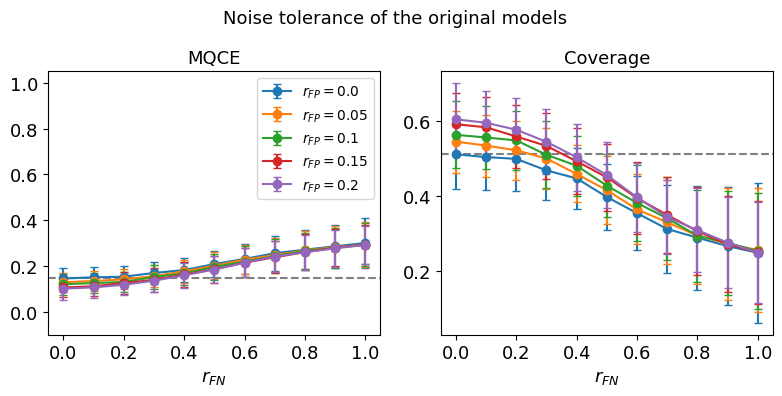

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

FONTSIZE = 13

plots = [
    ("mqce_final", "MQCE", (-0.1, 1.05)),
    ("coverage_final", "Coverage", None),
]

for ax, (metric, title, ylim) in zip(axes, plots):
    plot_one_accur_measure(ax, metric, cog_remov_add_accuracies_orig_models)

    ax.axhline(
        cog_remov_add_accuracies_orig_models[(0.0, 0.0)][metric][0],
        color="grey",
        linestyle="--",
        linewidth=1.5,
    )

    ax.set_title(title, fontsize=FONTSIZE)

    if ylim is not None:
        ax.set_ylim(*ylim)

axes[0].legend()

plt.suptitle("Noise tolerance of the original models", fontsize=FONTSIZE)
plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIRECTORY}/plots/noise_toler_orig_models_classif_regress_calibr.svg",
    format="svg",
    bbox_inches="tight",
)

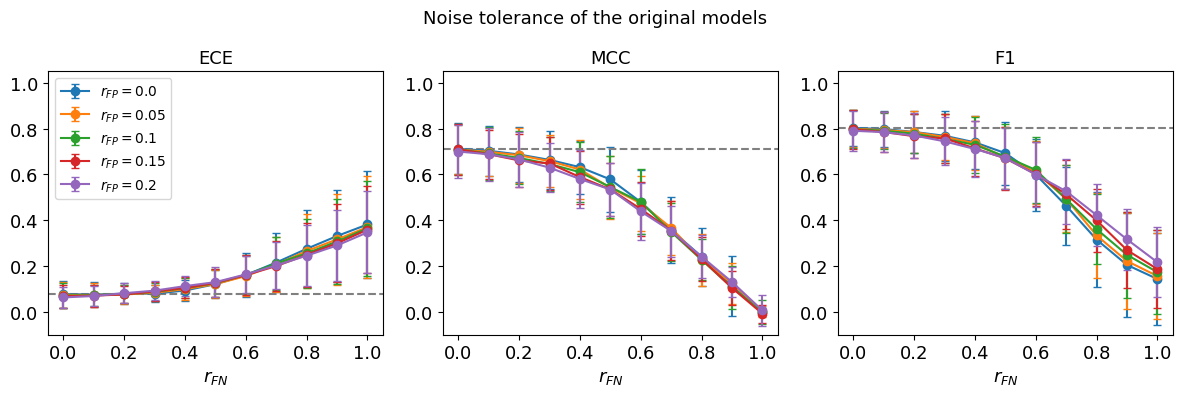

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

metrics = [
    ("ece", "ECE"),
    ("mcc", "MCC"),
    ("f1", "F1"),
]

for ax, (metric, title) in zip(axes, metrics):
    plot_one_accur_measure(ax, metric, cog_remov_add_accuracies_orig_models)

    ax.axhline(
        cog_remov_add_accuracies_orig_models[(0.0, 0.0)][metric][0],
        color="grey",
        linestyle="--",
        linewidth=1.5,
    )

    ax.set_ylim(-0.1, 1.05)
    ax.set_title(title, fontsize=FONTSIZE)

axes[0].legend()

plt.suptitle("Noise tolerance of the original models", fontsize=FONTSIZE)
plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIRECTORY}/plots/noise_toler_orig_models_classif.pdf",
    format="pdf",
    bbox_inches="tight",
)

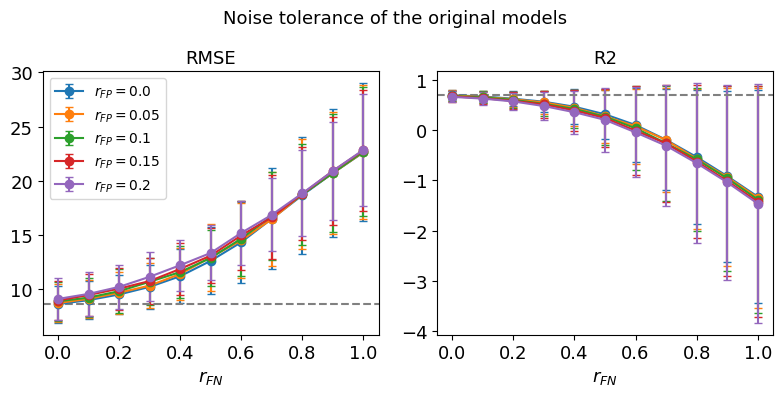

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

metrics = [
    ("rmse", "RMSE"),
    ("r2", "R2"),
]

for ax, (metric, title) in zip(axes, metrics):
    plot_one_accur_measure(ax, metric, cog_remov_add_accuracies_orig_models)

    ax.axhline(
        cog_remov_add_accuracies_orig_models[(0.0, 0.0)][metric][0],
        color="grey",
        linestyle="--",
        linewidth=1.5,
    )

    ax.set_title(title, fontsize=FONTSIZE)

axes[0].legend()

plt.suptitle("Noise tolerance of the original models", fontsize=FONTSIZE)
plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIRECTORY}/plots/noise_toler_orig_models_regr.pdf",
    format="pdf",
    bbox_inches="tight",
)

### 3. Noise tolerance of the models trained on noisy data

Here we train the original models for each train/test split and explore their performance on the noisy test data. The noise on the test dataset is implemented as the fraction false positives and false negatives.

#### 3.1 Analyze performance of the models on the high noise range [min_fp, max_fp], [min_fn, max_fn]

Processing noise types:   0%|                                                                         | 0/3 [00:00<?, ?it/s]

Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...


Processing noise types:  33%|█████████████████████▋                                           | 1/3 [00:02<00:05,  2.78s/it]

Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...


Processing noise types:  67%|███████████████████████████████████████████▎                     | 2/3 [00:05<00:03,  3.03s/it]

Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...


Processing noise types: 100%|█████████████████████████████████████████████████████████████████| 3/3 [00:08<00:00,  2.95s/it]


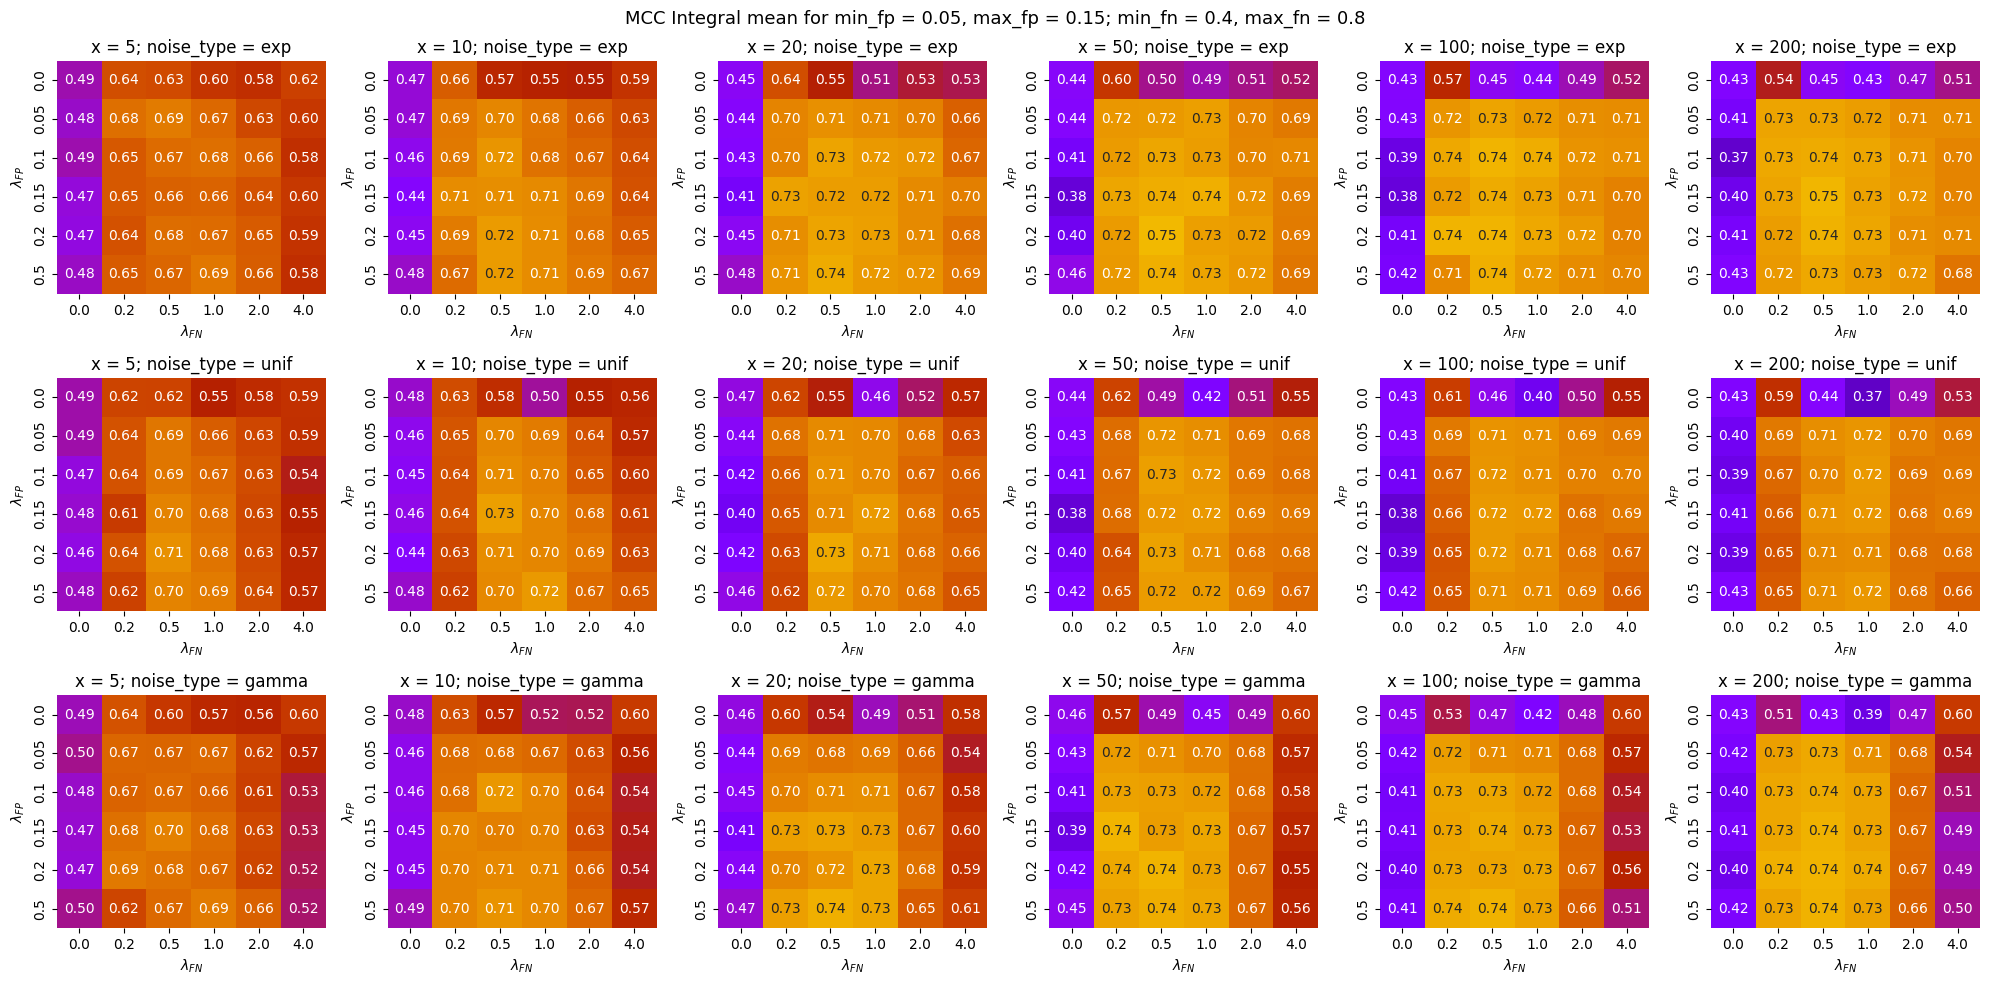

In [24]:
# Find the integrals of the MCC curves calculated for models trained on diffrent noise ranges and fisualize the result

from utils.utils_ancestral_predict import eval_trained_models_on_noisy_data, fp_curve_areas_one_model, fp_fn_surface_integral, plot_model_groups_surf_int, eval_trained_models_on_noisy_data_classif_and_regress

FONTSIZE = 13

# Specify the noise range for the test data
fn_rate_arr = [0.0, 0.2, 0.5, 1.0, 2.0, 4.0]
fp_rate_arr = [0.0, 0.05, 0.1, 0.15, 0.2, 0.5]
mean_rem_add_rates_tuples = [(add, rem) for add in fp_rate_arr for rem in fn_rate_arr]

# Specify the min and max noise ranges for the test data (the ranges for which the integrals will be calculated)
min_fn = 0.4
max_fn = 0.8

min_fp = 0.05
max_fp = 0.15

# Specify the paraters of the models trained on noise augmented data
x_range = [5, 10, 20, 50, 100, 200]#, 400]
noise_type_range = ["exp", "unif", "gamma"]

# Calculate the integrals for each trained model and visualize the result
fig, axes = plt.subplots(len(noise_type_range), len(x_range), figsize=(20,10))
for i, noise_type in enumerate(tqdm(noise_type_range, desc="Processing noise types")):
    for j, x in enumerate(x_range):
        ax = axes[i][j]
        filename_curve_dict = f"surf_area_mcc_integrals_min_fp_{min_fp}_max_fp_{max_fp}_min_fn_{min_fn}_max_fn_{max_fn}_noise_type_{noise_type}_x_{x}.pkl" 
        filepath = f"{OUTPUT_DIRECTORY}/{TRAINED_MOD_DIR}/{filename_curve_dict}"

        if os.path.exists(filepath):
            print("Loading the existing dict...")
            one_accur_dict = joblib.load(filepath)
        else:
            one_accur_dict = defaultdict(list)
            for fp_fn_tuple in mean_rem_add_rates_tuples:
                # Load the model
                filename = f"trained_models_fp_{fp_fn_tuple[0]}_fn_{fp_fn_tuple[1]}_noise_type_{noise_type}_x_{x}.pkl"
                loaded_models_dict = joblib.load(f"{OUTPUT_DIRECTORY}/{TRAINED_MOD_DIR}/{filename}")
                cog_remov_add_accuracies = eval_trained_models_on_noisy_data_classif_and_regress(loaded_models_dict, all_splits_dict, hard_fn_flag = True, min_fp = min_fp, min_fn = min_fn, max_fp = max_fp, max_fn = max_fn,n_jobs=-1, truncated_feature_set=None, test_or_val="val")#eval_trained_models_on_noisy_data(all_splits_dict, loaded_models_dict, hard_fn_flag = True, min_fp = min_fp, min_fn = min_fn, max_fp = max_fp, max_fn = max_fn, test_or_val = "val")
 
                # Find the FP curves integrals on range [max_fp, max_fn]
                metric = 'mcc'
                fp_surface_integral = fp_fn_surface_integral(metric, min_fp, max_fp, min_fn, max_fn, cog_remov_add_accuracies)#fp_curve_areas_one_model(metric, max_fp, max_fn, cog_remov_add_accuracies)     
                one_accur_dict[fp_fn_tuple] = fp_surface_integral

            joblib.dump(one_accur_dict, filepath)
            print("Saving the dict...")

        plot_model_groups_surf_int(one_accur_dict, ax, vmin=0.3, vmax=0.8, cmap="gnuplot")
        ax.set_title(f"x = {x}; noise_type = {noise_type}")
        ax.set_xlabel(r"$\lambda_{FN}$")
        ax.set_ylabel(r"$\lambda_{FP}$")

plt.suptitle(rf"MCC Integral mean for min_fp = {min_fp}, max_fp = {max_fp}; min_fn = {min_fn}, max_fn = {max_fn}", fontsize=FONTSIZE)
plt.tight_layout()

plt.savefig(f"{OUTPUT_DIRECTORY}/plots/mcc_integral_actoss_noise.svg", format="svg", bbox_inches='tight')

Processing noise types:   0%|                                                                         | 0/3 [00:00<?, ?it/s]

Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...


Processing noise types:  33%|█████████████████████▋                                           | 1/3 [00:02<00:05,  2.77s/it]

Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...


Processing noise types:  67%|███████████████████████████████████████████▎                     | 2/3 [00:05<00:02,  2.85s/it]

Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...


Processing noise types: 100%|█████████████████████████████████████████████████████████████████| 3/3 [00:08<00:00,  2.97s/it]


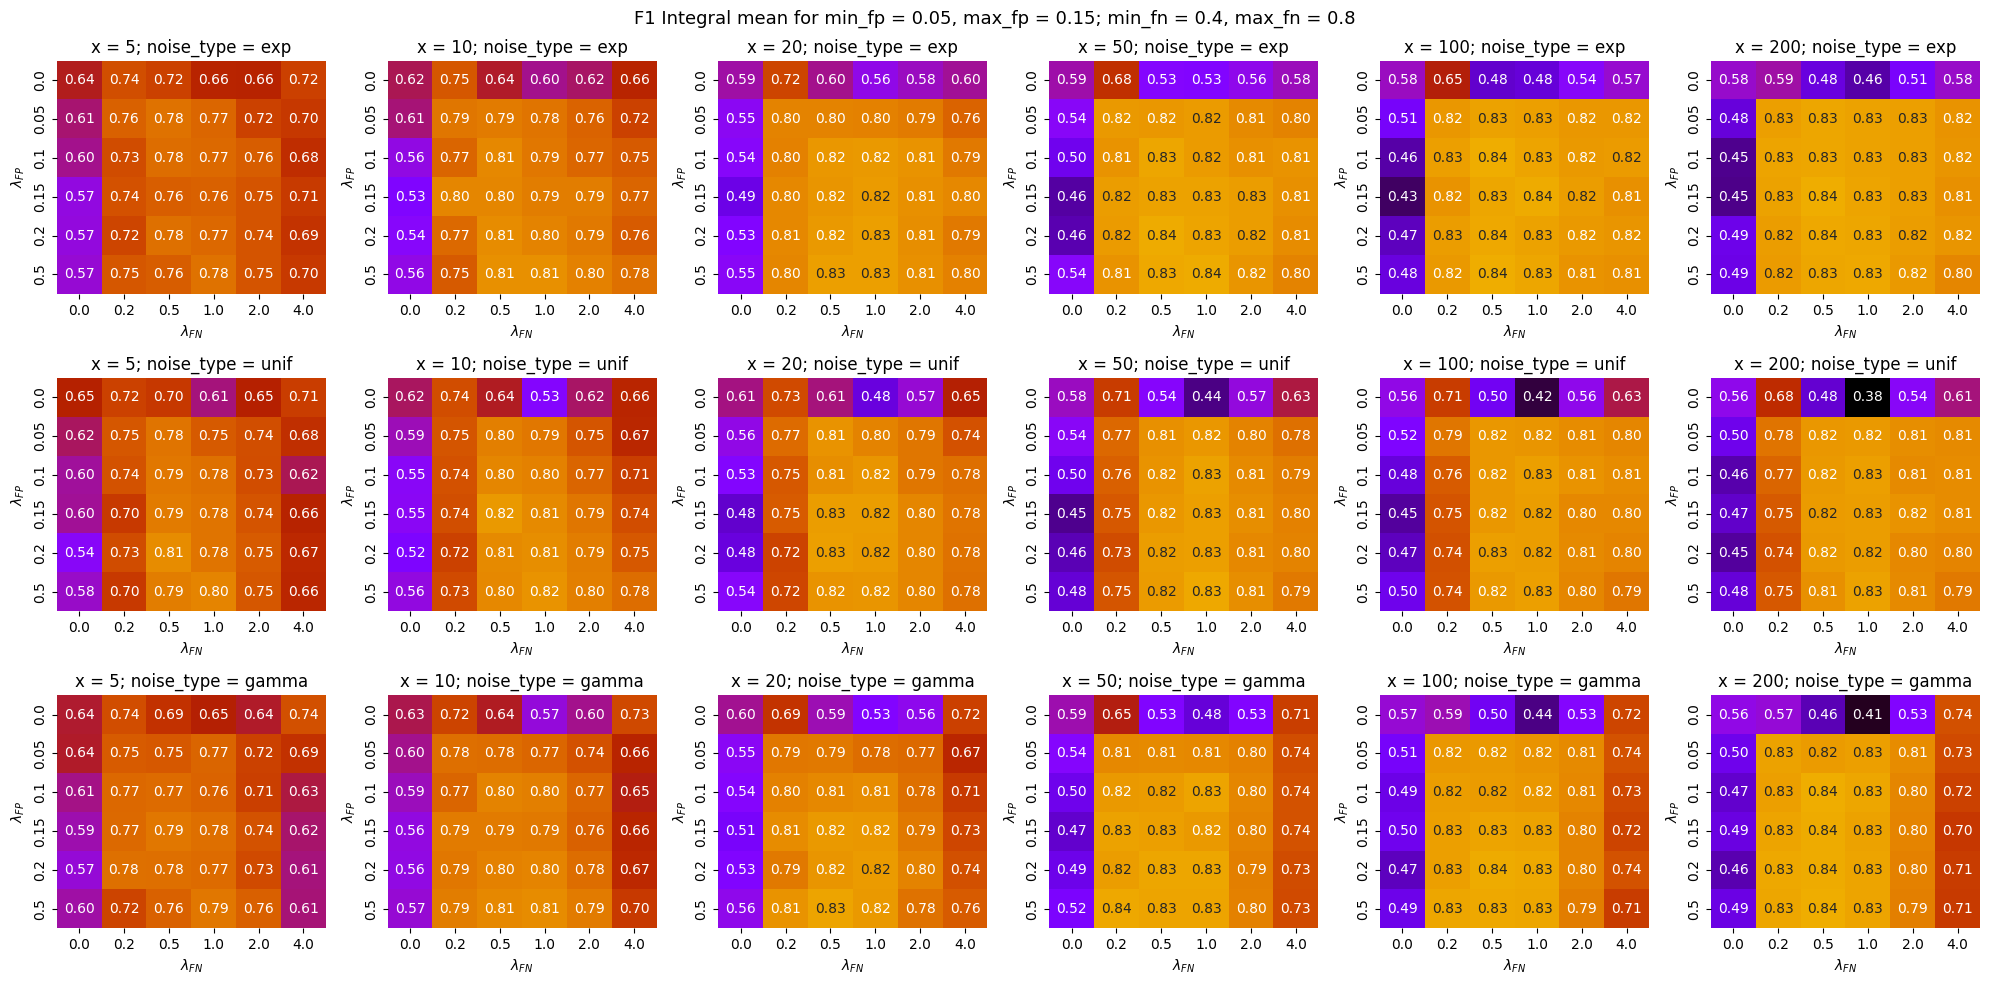

In [25]:
# Find the integrals of the F1 curves calculated for models trained on diffrent noise ranges and fisualize the result

fig, axes = plt.subplots(len(noise_type_range), len(x_range), figsize=(20,10))
for i, noise_type in enumerate(tqdm(noise_type_range, desc="Processing noise types")):
    for j, x in enumerate(x_range):
        ax = axes[i][j]
        filename_curve_dict = f"surf_area_f1_integrals_min_fp_{min_fp}_max_fp_{max_fp}_min_fn_{min_fn}_max_fn_{max_fn}_noise_type_{noise_type}_x_{x}.pkl" 
        filepath = f"{OUTPUT_DIRECTORY}/{TRAINED_MOD_DIR}/{filename_curve_dict}"

        if os.path.exists(filepath):
            print("Loading the existing dict...")
            one_accur_dict = joblib.load(filepath)
        else:
            one_accur_dict = defaultdict(list)
            for fp_fn_tuple in mean_rem_add_rates_tuples:
                # Load the model
                filename = f"trained_models_fp_{fp_fn_tuple[0]}_fn_{fp_fn_tuple[1]}_noise_type_{noise_type}_x_{x}.pkl"
                loaded_models_dict = joblib.load(f"{OUTPUT_DIRECTORY}/{TRAINED_MOD_DIR}/{filename}")
                cog_remov_add_accuracies = eval_trained_models_on_noisy_data_classif_and_regress(loaded_models_dict, all_splits_dict, hard_fn_flag = True, min_fp = min_fp, min_fn = min_fn, max_fp = max_fp, max_fn = max_fn)#eval_trained_models_on_noisy_data(all_splits_dict, loaded_models_dict, hard_fn_flag = True, min_fp = min_fp, min_fn = min_fn, max_fp = max_fp, max_fn = max_fn, test_or_val = "val")
    
                # Find the FP curves integrals on range [max_fp, max_fn]
                metric = 'f1'
                fp_surface_integral = fp_fn_surface_integral(metric, min_fp, max_fp, min_fn, max_fn, cog_remov_add_accuracies)#fp_curve_areas_one_model(metric, max_fp, max_fn, cog_remov_add_accuracies)     
                one_accur_dict[fp_fn_tuple] = fp_surface_integral

            joblib.dump(one_accur_dict, filepath)
            print("Saving the dict...")

        plot_model_groups_surf_int(one_accur_dict, ax, vmin=0.4, vmax=0.9, cmap="gnuplot")
        ax.set_title(f"x = {x}; noise_type = {noise_type}")
        ax.set_xlabel(r"$\lambda_{FN}$")
        ax.set_ylabel(r"$\lambda_{FP}$")

plt.suptitle(rf"F1 Integral mean for min_fp = {min_fp}, max_fp = {max_fp}; min_fn = {min_fn}, max_fn = {max_fn}", fontsize=FONTSIZE)
plt.tight_layout()

plt.savefig(f"{OUTPUT_DIRECTORY}/plots/f1_integral_actoss_noise.svg", format="svg", bbox_inches='tight')

Processing noise types:   0%|                                                                         | 0/3 [00:00<?, ?it/s]

Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...


Processing noise types:  33%|█████████████████████▋                                           | 1/3 [00:02<00:05,  2.75s/it]

Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...


Processing noise types:  67%|███████████████████████████████████████████▎                     | 2/3 [00:05<00:02,  2.89s/it]

Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...


Processing noise types: 100%|█████████████████████████████████████████████████████████████████| 3/3 [00:08<00:00,  2.69s/it]


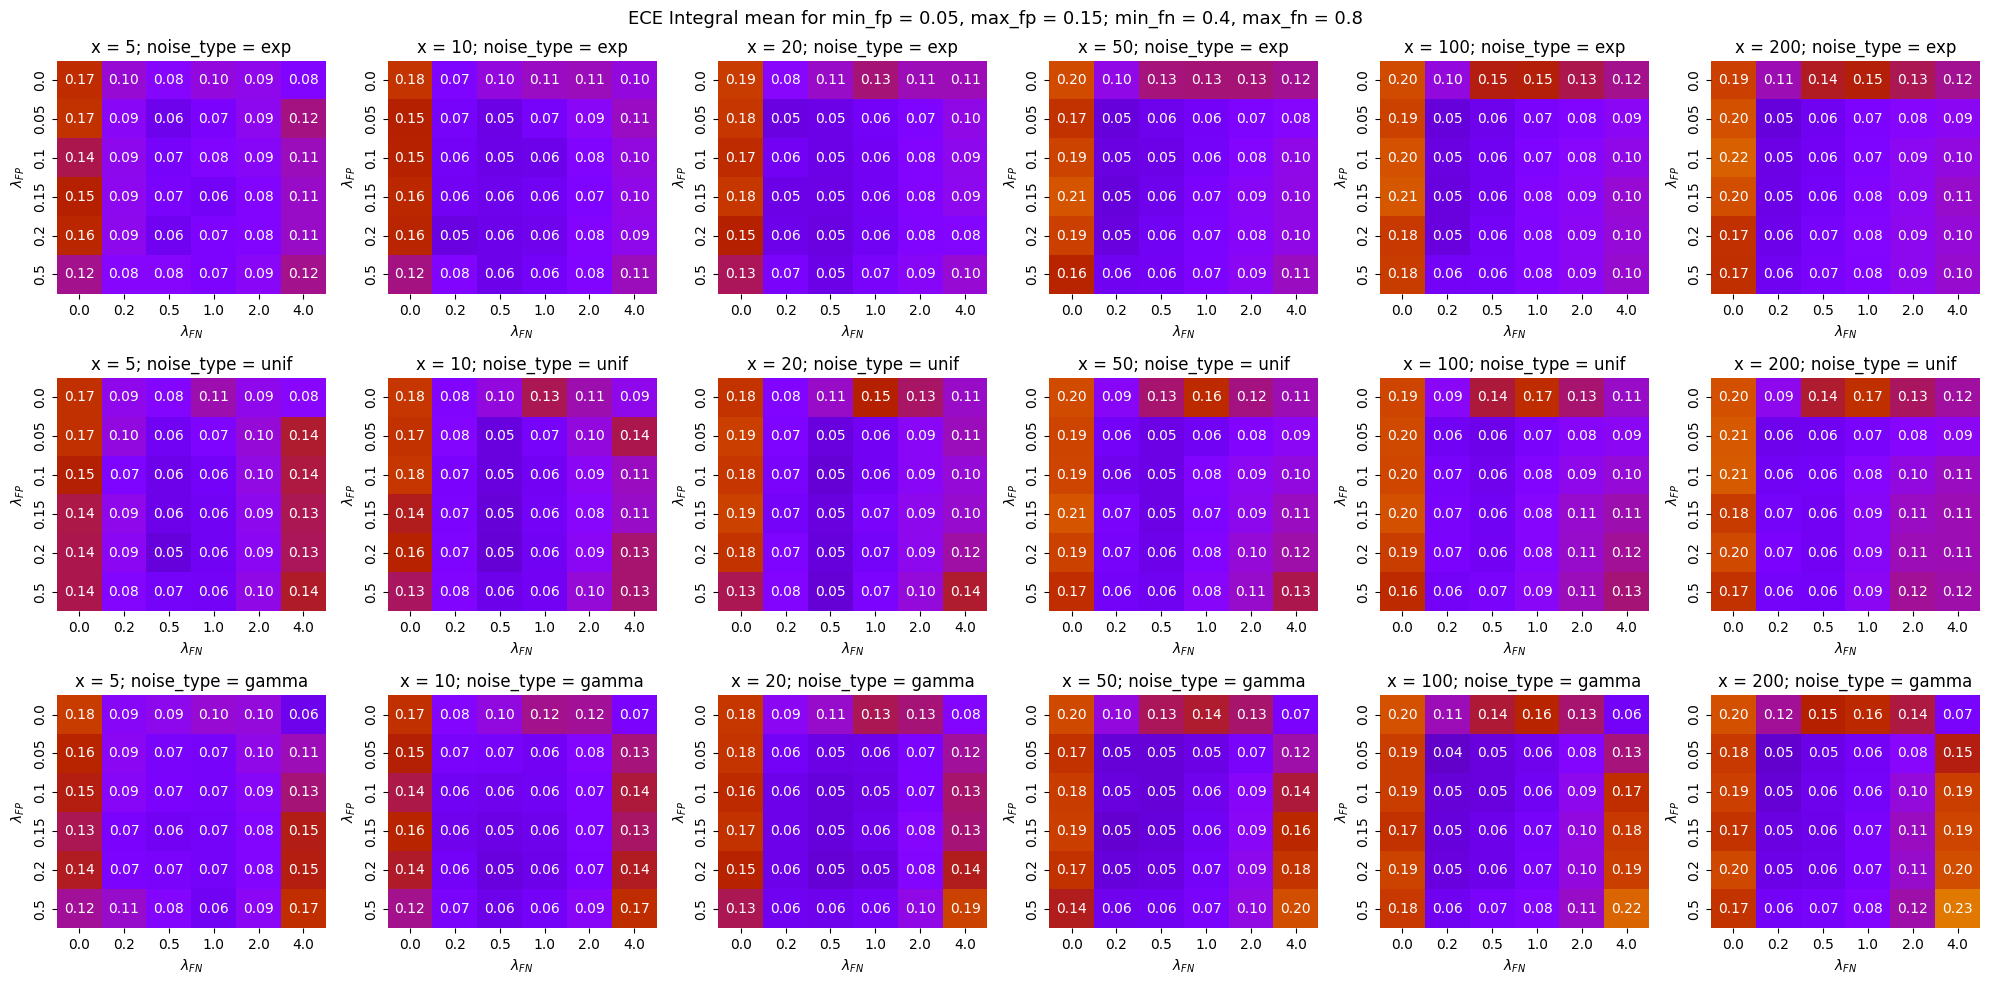

In [26]:
# Find the integrals of the ECE curves calculated for models trained on diffrent noise ranges and fisualize the result

fig, axes = plt.subplots(len(noise_type_range), len(x_range), figsize=(20,10))
for i, noise_type in enumerate(tqdm(noise_type_range, desc="Processing noise types")):
    for j, x in enumerate(x_range):
        ax = axes[i][j]
        filename_curve_dict = f"surf_area_ece_integrals_min_fp_{min_fp}_max_fp_{max_fp}_min_fn_{min_fn}_max_fn_{max_fn}_noise_type_{noise_type}_x_{x}.pkl" 
        filepath = f"{OUTPUT_DIRECTORY}/{TRAINED_MOD_DIR}/{filename_curve_dict}"

        if os.path.exists(filepath):
            print("Loading the existing dict...")
            one_accur_dict = joblib.load(filepath)
        else:
            one_accur_dict = defaultdict(list)
            for fp_fn_tuple in mean_rem_add_rates_tuples:
                # Load the model
                filename = f"trained_models_fp_{fp_fn_tuple[0]}_fn_{fp_fn_tuple[1]}_noise_type_{noise_type}_x_{x}.pkl"
                loaded_models_dict = joblib.load(f"{OUTPUT_DIRECTORY}/{TRAINED_MOD_DIR}/{filename}")
                cog_remov_add_accuracies = eval_trained_models_on_noisy_data_classif_and_regress(loaded_models_dict, all_splits_dict, hard_fn_flag = True, min_fp = min_fp, min_fn = min_fn, max_fp = max_fp, max_fn = max_fn)#eval_trained_models_on_noisy_data(all_splits_dict, loaded_models_dict, hard_fn_flag = True, min_fp = min_fp, min_fn = min_fn, max_fp = max_fp, max_fn = max_fn, test_or_val = "val")
    
                # Find the FP curves integrals on range [max_fp, max_fn]
                metric = 'ece'
                fp_surface_integral = fp_fn_surface_integral(metric, min_fp, max_fp, min_fn, max_fn, cog_remov_add_accuracies)#fp_curve_areas_one_model(metric, max_fp, max_fn, cog_remov_add_accuracies)     
                one_accur_dict[fp_fn_tuple] = fp_surface_integral

            joblib.dump(one_accur_dict, filepath)
            print("Saving the dict...")

        plot_model_groups_surf_int(one_accur_dict, ax, vmin=0.0, vmax=0.3, cmap="gnuplot")
        ax.set_title(f"x = {x}; noise_type = {noise_type}")
        ax.set_xlabel(r"$\lambda_{FN}$")
        ax.set_ylabel(r"$\lambda_{FP}$")

plt.suptitle(rf"ECE Integral mean for min_fp = {min_fp}, max_fp = {max_fp}; min_fn = {min_fn}, max_fn = {max_fn}", fontsize=FONTSIZE)
plt.tight_layout()

plt.savefig(f"{OUTPUT_DIRECTORY}/plots/ece_integral_actoss_noise.svg", format="svg", bbox_inches='tight')

Processing noise types:   0%|                                                                         | 0/3 [00:00<?, ?it/s]

Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...


Processing noise types:  33%|█████████████████████▋                                           | 1/3 [00:03<00:06,  3.20s/it]

Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...


Processing noise types:  67%|███████████████████████████████████████████▎                     | 2/3 [00:05<00:02,  2.51s/it]

Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...


Processing noise types: 100%|█████████████████████████████████████████████████████████████████| 3/3 [00:07<00:00,  2.52s/it]


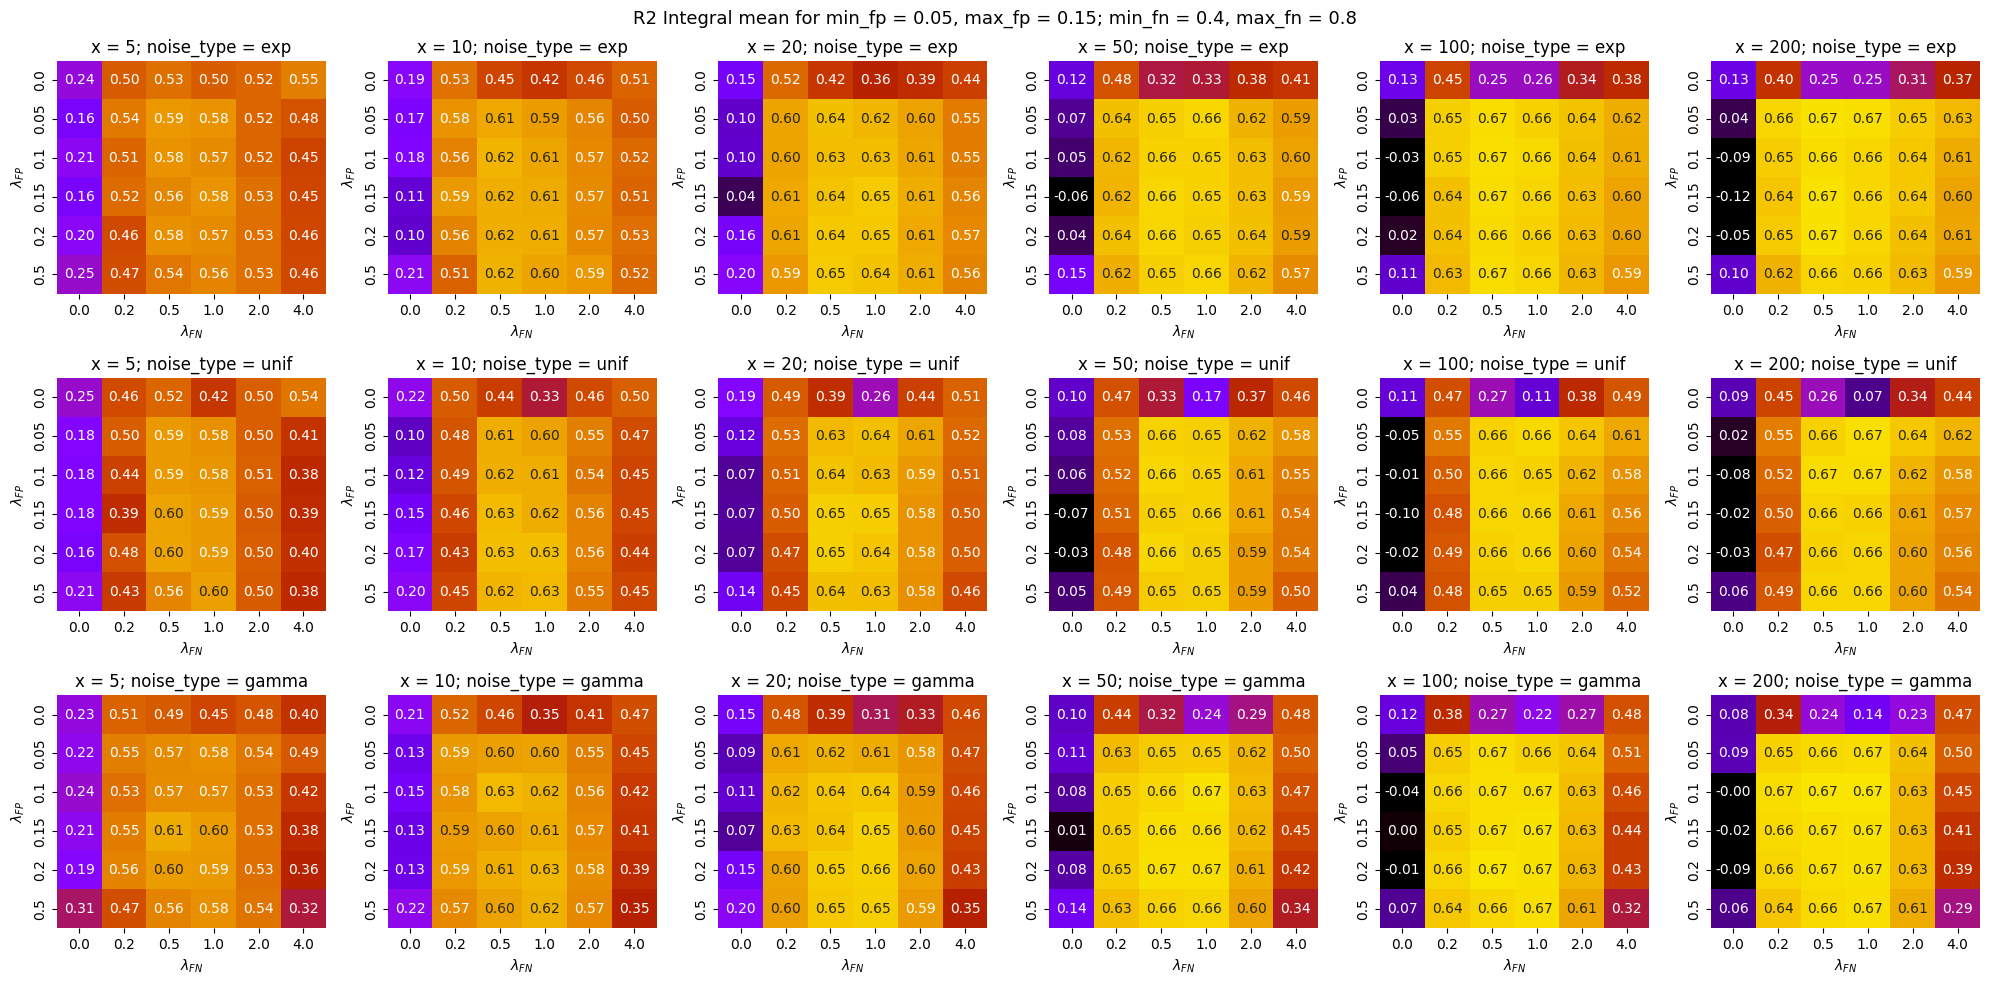

In [27]:
# Find the integrals of the R2 curves calculated for models trained on diffrent noise ranges and fisualize the result

fig, axes = plt.subplots(len(noise_type_range), len(x_range), figsize=(20,10))
for i, noise_type in enumerate(tqdm(noise_type_range, desc="Processing noise types")):
    for j, x in enumerate(x_range):
        ax = axes[i][j]
        filename_curve_dict = f"surf_area_r2_integrals_min_fp_{min_fp}_max_fp_{max_fp}_min_fn_{min_fn}_max_fn_{max_fn}_noise_type_{noise_type}_x_{x}.pkl" 
        filepath = f"{OUTPUT_DIRECTORY}/{TRAINED_MOD_DIR}/{filename_curve_dict}"

        if os.path.exists(filepath):
            print("Loading the existing dict...")
            one_accur_dict = joblib.load(filepath)
        else:
            one_accur_dict = defaultdict(list)
            for fp_fn_tuple in mean_rem_add_rates_tuples:
                # Load the model
                filename = f"trained_models_fp_{fp_fn_tuple[0]}_fn_{fp_fn_tuple[1]}_noise_type_{noise_type}_x_{x}.pkl"
                loaded_models_dict = joblib.load(f"{OUTPUT_DIRECTORY}/{TRAINED_MOD_DIR}/{filename}")
                cog_remov_add_accuracies = eval_trained_models_on_noisy_data_classif_and_regress(loaded_models_dict, all_splits_dict, hard_fn_flag = True, min_fp = min_fp, min_fn = min_fn, max_fp = max_fp, max_fn = max_fn)#eval_trained_models_on_noisy_data(all_splits_dict, loaded_models_dict, hard_fn_flag = True, min_fp = min_fp, min_fn = min_fn, max_fp = max_fp, max_fn = max_fn, test_or_val = "val")
    
                # Find the FP curves integrals on range [max_fp, max_fn]
                metric = 'r2'
                fp_surface_integral = fp_fn_surface_integral(metric, min_fp, max_fp, min_fn, max_fn, cog_remov_add_accuracies)#fp_curve_areas_one_model(metric, max_fp, max_fn, cog_remov_add_accuracies)     
                one_accur_dict[fp_fn_tuple] = fp_surface_integral

            joblib.dump(one_accur_dict, filepath)
            print("Saving the dict...")

        plot_model_groups_surf_int(one_accur_dict, ax, vmin=0.0, vmax=0.7, cmap="gnuplot")
        ax.set_title(f"x = {x}; noise_type = {noise_type}")
        ax.set_xlabel(r"$\lambda_{FN}$")
        ax.set_ylabel(r"$\lambda_{FP}$")

plt.suptitle(rf"R2 Integral mean for min_fp = {min_fp}, max_fp = {max_fp}; min_fn = {min_fn}, max_fn = {max_fn}", fontsize=FONTSIZE)
plt.tight_layout()

plt.savefig(f"{OUTPUT_DIRECTORY}/plots/r2_integral_actoss_noise.svg", format="svg", bbox_inches='tight')

In [28]:
f"{OUTPUT_DIRECTORY}/plots/r2_integral_actoss_noise.svg"

'../data_ogt/outputs/COG_aa/phylum/plots/r2_integral_actoss_noise.svg'

#### 3.2  Visualize the performance improvement for the chosen model

In [15]:
# Choose a model
x_noisy_samples = 100
fp_rate_mean = 0.1
fn_rate_mean = 0.5
noise_type = "exp"

# Load a pre-trained model
filename = f"trained_models_fp_{fp_rate_mean}_fn_{fn_rate_mean}_noise_type_{noise_type}_x_{x_noisy_samples}.pkl"
loaded_models_dict = joblib.load(f"{OUTPUT_DIRECTORY}/trained_models_train_val_test/{filename}")

In [16]:
# f"{OUTPUT_DIRECTORY}/trained_models_train_val_test/{filename}"

In [17]:
# f"{OUTPUT_DIRECTORY}/trained_models_train_val_test/{filename}"

In [18]:
noise_robust_trained_models_filename = (
    f"{OUTPUT_DIRECTORY}/trained_models_train_val_test/trained_models"
    f"_fp_{fp_rate_mean}_fn_{fn_rate_mean}"
    f"_noise_type_{noise_type}_x_{x_noisy_samples}.pkl"
)
os.path.exists(noise_robust_trained_models_filename)

True

In [25]:
# Re-train the chosen models, and calculate MQCE for them (the other pre-trained model don't have MQCE due to high computational cost)

from utils.utils_ancestral_predict import augment_data_with_noise

temp_bound = OGT_BOUNDARY

if os.path.exists(noise_robust_trained_models_filename):
    print("Loading existing pre-trained models...")
    noise_robust_trained_models = joblib.load(f"{OUTPUT_DIRECTORY}/trained_models_train_val_test/{filename}")
else:
    print("Training models from scratch...")

    noise_robust_trained_models = {}
    for split_id in range(2):#tqdm(all_splits_dict.keys(), desc="Training splits"): #all_splits_dict.keys()
        X_val_train = all_splits_dict[split_id]["X_train"]
        y_label_train = all_splits_dict[split_id]["y_train"]
    
        X_augmented, y_augmented = augment_data_with_noise(X_val_train, y_label_train, n_clones=x_noisy_samples, mean_fp=fp_rate_mean, mean_fn=fn_rate_mean, noise_type=noise_type)
    
    
        range_labels = label_ogt_range(y_augmented)
        le = LabelEncoder()
        range_ids = le.fit_transform(range_labels)  
        label_to_int = {'low': 0, 'high': 1}
        range_ids = np.vectorize(label_to_int.get)(range_labels)
    
        classes = np.unique(range_ids)
        weights = compute_class_weight(class_weight='balanced', classes=classes, y=range_ids)
        class_weights = dict(zip(classes, weights))
        sample_weights = np.array([class_weights[c] for c in range_ids])
    
        sample_weights_np = sample_weights if isinstance(sample_weights, np.ndarray) else sample_weights.cpu().numpy()
        range_ids_np = range_ids if isinstance(range_ids, np.ndarray) else range_ids.cpu().numpy()
    
        # 1. Classifier model
        gating_model_with_noise = make_xgb()
        gating_model_with_noise.fit(X_augmented, range_ids, sample_weight=sample_weights)
    
        # Convert to numpy
        X_train_np = X_augmented.cpu().numpy()
        y_train_np = y_augmented.cpu().numpy().flatten()
        
        # Right and left regressors
        low_mask = y_train_np < temp_bound
        high_mask = y_train_np >= temp_bound
    
        # Train the left and right regressors
        model_low_with_noise = make_xgb_regressor()
        model_high_with_noise = make_xgb_regressor()
        model_low_with_noise.fit(X_train_np[low_mask], y_train_np[low_mask])
        model_high_with_noise.fit(X_train_np[high_mask], y_train_np[high_mask])
    
        # Lower bound regressors (e.g. 10th percentile)
        model_low_q10 = make_xgb_quantile_regressor(0.1)
        model_high_q10 = make_xgb_quantile_regressor(0.1)
        
        # Upper bound regressors (e.g. 90th percentile)
        model_low_q90 = make_xgb_quantile_regressor(0.9)
        model_high_q90 = make_xgb_quantile_regressor(0.9)
        
        model_low_q10.fit(X_train_np[low_mask], y_train_np[low_mask])
        model_low_q90.fit(X_train_np[low_mask], y_train_np[low_mask])
        
        model_high_q10.fit(X_train_np[high_mask], y_train_np[high_mask])
        model_high_q90.fit(X_train_np[high_mask], y_train_np[high_mask])
        
        noise_robust_trained_models[split_id] = (gating_model_with_noise, model_low_with_noise, model_high_with_noise, model_low_q10, model_low_q90, model_high_q10, model_high_q90)
    
    joblib.dump(noise_robust_trained_models, f"{OUTPUT_DIRECTORY}/trained_models_train_val_test/{filename}")

Loading existing pre-trained models...


In [ ]:
# from utils.utils_ancestral_predict import  eval_trained_models_on_noisy_data_classif_and_regress

# cog_remov_add_accuracies_noise_models_filename = (
#     f"{OUTPUT_DIRECTORY}/cog_remov_add_accuracies_noise_models_fp_{fp_rate_mean}_fn_{fn_rate_mean}_noise_type_{noise_type}_x_{x_noisy_samples}"
# )

# cog_remov_add_accuracies = eval_trained_models_on_noisy_data_classif_and_regress(loaded_models_dict, all_splits_dict, hard_fn_flag = True, test_or_val = "test") #noise_robust_trained_models

In [26]:
import os
import pickle

from utils.utils_ancestral_predict import (
    eval_trained_models_on_noisy_data_classif_and_regress,
)

cog_remov_add_accuracies_noise_models_filename = (
    f"{OUTPUT_DIRECTORY}/cog_remov_add_accuracies_noise_models"
    f"_fp_{fp_rate_mean}_fn_{fn_rate_mean}"
    f"_noise_type_{noise_type}_x_{x_noisy_samples}"
)

if False:#os.path.exists(cog_remov_add_accuracies_noise_models_filename):
    with open(cog_remov_add_accuracies_noise_models_filename, "rb") as f:
        cog_remov_add_accuracies = pickle.load(f)

    print(f"Loaded existing results from {cog_remov_add_accuracies_noise_models_filename}")

else:
    print("Calculating new accuracies...")
    cog_remov_add_accuracies = (
        eval_trained_models_on_noisy_data_classif_and_regress(
            noise_robust_trained_models,
            all_splits_dict,
            hard_fn_flag=True,
            test_or_val="test",
        )
    )

    os.makedirs(OUTPUT_DIRECTORY, exist_ok=True)

    with open(cog_remov_add_accuracies_noise_models_filename, "wb") as f:
        pickle.dump(cog_remov_add_accuracies, f)

    print(f"Calculated and saved results to {cog_remov_add_accuracies_noise_models_filename}")

Calculating new accuracies...


/flash/SzollosiU/anzhelika-koldaeva/gene-context/mlm/pytorch_3.11/lib/python3.11/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Calculated and saved results to ../data_ogt/outputs/COG_aa/phylum/cog_remov_add_accuracies_noise_models_fp_0.1_fn_0.5_noise_type_exp_x_100


In [28]:
allowed_fp = {0.0, 0.1, 0.2}

cog_remov_add_accuracies_filtered = {
    k: v
    for k, v in cog_remov_add_accuracies.items()
    if k[1] in allowed_fp
}

cog_remov_add_accuracies_orig_models_filtered = {
    k: v
    for k, v in cog_remov_add_accuracies_orig_models.items()
    if k[1] in allowed_fp
}

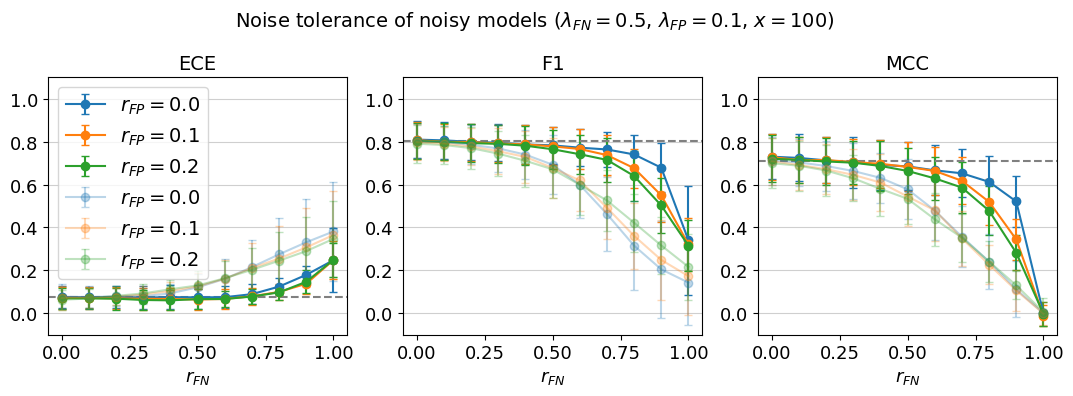

In [29]:
import matplotlib.pyplot as plt

FONTSIZE = 14

fig, axes = plt.subplots(1, 3, figsize=(10.8, 4))

metrics = [
    ("ece", "ECE"),
    ("f1", "F1"),
    ("mcc", "MCC"),
]

for ax, (metric, title) in zip(axes, metrics):
    plot_one_accur_measure(ax, metric, cog_remov_add_accuracies_filtered)
    plot_one_accur_measure(ax, metric, cog_remov_add_accuracies_orig_models_filtered, alpha=0.3)

    ax.axhline(
        cog_remov_add_accuracies_orig_models_filtered[(0.0, 0.0)][metric][0],
        color="grey",
        linestyle="--",
        linewidth=1.5,
    )

    ax.set_ylim(-0.1, 1.1)
    ax.set_title(title, fontsize=FONTSIZE)
    ax.grid(axis="y", alpha=0.6)

axes[0].legend(fontsize=FONTSIZE)

plt.suptitle(
    rf"Noise tolerance of noisy models ($\lambda_{{FN}}={fn_rate_mean}$, "
    rf"$\lambda_{{FP}}={fp_rate_mean}$, $x={x_noisy_samples}$)",
    fontsize=FONTSIZE,
)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIRECTORY}/plots/"
    f"noise_toler_noisy_model_FP_{fp_rate_mean}_"
    f"FN_{fn_rate_mean}_x_{x_noisy_samples}_classif.svg",
    format="svg",
    bbox_inches="tight",
)

In [38]:
f"{OUTPUT_DIRECTORY}/plots/noise_toler_noisy_model_FP_{fp_rate_mean}_FN_{fn_rate_mean}_x_{x_noisy_samples}_classif.svg"

'../data_ogt/outputs/COG_aa/phylum/plots/noise_toler_noisy_model_FP_0.1_FN_0.5_x_100_classif.svg'

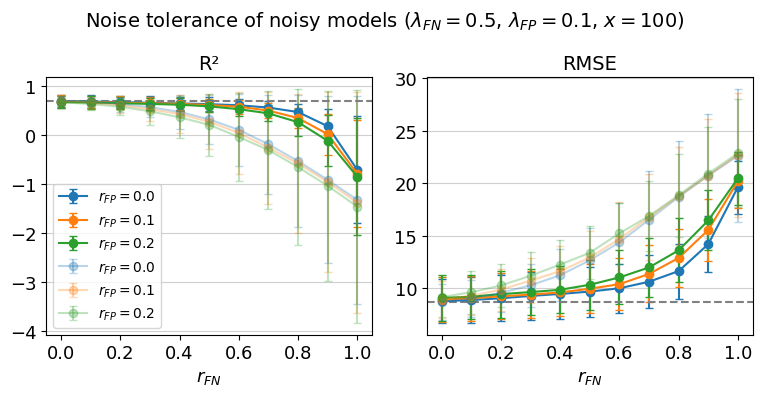

In [35]:
import matplotlib.pyplot as plt

FONTSIZE = 14

fig, axes = plt.subplots(1, 2, figsize=(7.8, 4))

metrics = [
    ("r2", "R²"),
    ("rmse", "RMSE"),
]

for ax, (metric, title) in zip(axes, metrics):
    plot_one_accur_measure(ax, metric, cog_remov_add_accuracies_filtered)
    plot_one_accur_measure(ax, metric, cog_remov_add_accuracies_orig_models_filtered, alpha=0.3)

    ax.axhline(
        cog_remov_add_accuracies_orig_models_filtered[(0.0, 0.0)][metric][0],
        color="grey",
        linestyle="--",
        linewidth=1.5,
    )

    ax.set_title(title, fontsize=FONTSIZE)
    ax.grid(axis="y", alpha=0.6)

axes[0].legend()

plt.suptitle(
    rf"Noise tolerance of noisy models "
    rf"($\lambda_{{FN}}={fn_rate_mean}$, "
    rf"$\lambda_{{FP}}={fp_rate_mean}$, "
    rf"$x={x_noisy_samples}$)",
    fontsize=FONTSIZE,
)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIRECTORY}/plots/"
    f"noise_toler_noisy_model_FP_{fp_rate_mean}_"
    f"FN_{fn_rate_mean}_x_{x_noisy_samples}_regress.svg",
    format="svg",
    bbox_inches="tight",
)

In [39]:
f"{OUTPUT_DIRECTORY}/plots/noise_toler_noisy_model_FP_{fp_rate_mean}_FN_{fn_rate_mean}_x_{x_noisy_samples}_regress.svg"

'../data_ogt/outputs/COG_aa/phylum/plots/noise_toler_noisy_model_FP_0.1_FN_0.5_x_100_regress.svg'

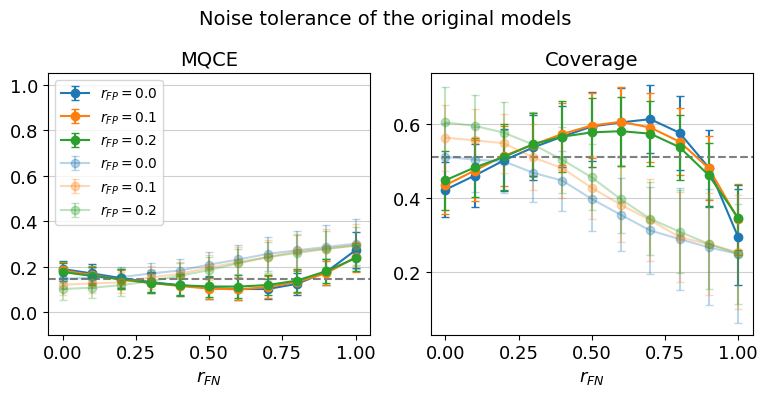

In [41]:
import matplotlib.pyplot as plt

FONTSIZE = 14

fig, axes = plt.subplots(1, 2, figsize=(7.8, 4))

metrics = [
    ("mqce_final", "MQCE", (-0.1, 1.05)),
    ("coverage_final", "Coverage", None),
]

for ax, (metric, title, ylim) in zip(axes, metrics):
    plot_one_accur_measure(ax, metric, cog_remov_add_accuracies_filtered)
    plot_one_accur_measure(ax, metric, cog_remov_add_accuracies_orig_models_filtered, alpha=0.3)

    ax.axhline(
        cog_remov_add_accuracies_orig_models_filtered[(0.0, 0.0)][metric][0],
        color="grey",
        linestyle="--",
        linewidth=1.5,
    )

    ax.set_title(title, fontsize=FONTSIZE)
    ax.grid(axis="y", alpha=0.6)

    if ylim is not None:
        ax.set_ylim(*ylim)

axes[0].legend()

plt.suptitle("Noise tolerance of the original models", fontsize=FONTSIZE)
plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIRECTORY}/plots/"
    f"noise_toler_noisy_model_FP_{fp_rate_mean}_"
    f"FN_{fn_rate_mean}_x_{x_noisy_samples}_{metric}_regress_calibr.svg",
    format="svg",
    bbox_inches="tight",
)

In [40]:
f"{OUTPUT_DIRECTORY}/plots/noise_toler_noisy_model_FP_{fp_rate_mean}_FN_{fn_rate_mean}_x_{x_noisy_samples}_{metric}_regress_calibr.svg"

'../data_ogt/outputs/COG_aa/phylum/plots/noise_toler_noisy_model_FP_0.1_FN_0.5_x_100_coverage_final_regress_calibr.svg'

#### 3.2  Visualize the performance improvement for the chosen model across evo distancies

In [7]:
import pandas as pd
from Bio import Phylo

TIME_UNIT_FACTOR = 1.0   # 1000 if branch lengths are in Ga
TREE_FILE = "../ancestral_data/C65.tree"
GENOMES_INFO = "../ancestral_data/GenomesInfo.csv"
BAC_TSV = "../data_preparation/gtdb_files/bac120_metadata_r202.tsv"
ARC_TSV = "../data_preparation/gtdb_files/ar122_metadata_r202.tsv"

RANKS = ["domain", "phylum", "class", "order", "family", "genus", "species"]
RANK_IDX = {r: i for i, r in enumerate(RANKS)} 

In [8]:
from utils.utils_ancestral_predict import norm

# ---- 1. Load the tree, build parent links and node ages ----
tree = Phylo.read(TREE_FILE, "newick")

parent = {}   # id(child clade) -> parent clade
age = {}      # id(clade) -> age (Ma before present)
for clade in tree.find_clades(order="postorder"):
    if clade.is_terminal():
        age[id(clade)] = 0.0
    else:
        age[id(clade)] = float(np.mean([age[id(c)] + (c.branch_length or 0.0) for c in clade.clades]))
        for c in clade.clades:
            parent[id(c)] = clade

leaf_by_name = {norm(t.name): t for t in tree.get_terminals()}
print(f"Tree has {len(leaf_by_name)} tips; root age = {age[id(tree.root)] * TIME_UNIT_FACTOR:.1f} Ma")

Tree has 1007 tips; root age = 4333.2 Ma


In [9]:
from utils.utils_ancestral_predict import acc_key

# ---- 2. Map accessions -> tree tip names (GenomesInfo.csv) ----
info = pd.read_csv(GENOMES_INFO, sep=",")
print("GenomesInfo columns:", info.columns.tolist())

# Detect which column holds tip names and which holds accessions
tip_col = next(c for c in info.columns
               if info[c].astype(str).map(norm).isin(set(leaf_by_name)).mean() > 0.5)
acc_col = next(c for c in info.columns
               if info[c].astype(str).str.contains(r"GC[AF]_\d+").mean() > 0.5)
print(f"tip column = '{tip_col}', accession column = '{acc_col}'")

acc_to_tip = dict(zip(info[acc_col].astype(str).map(acc_key),
                      info[tip_col].astype(str).map(norm)))
print(f"{len(acc_to_tip)} accessions linked to tree tips")

GenomesInfo columns: ['accession', 'ShortCode', 'r202_accession', 'checkm_completeness', 'checkm_contamination', 'quality', 'genome_size', 'gc_percentage', 'gtdb_type_designation', 'gtdb_genome_representative', 'gtdb_representative', 'ncbi_taxid', 'gtdb_taxonomy', 'phylum', 'class', 'order', 'family', 'genus', 'sp', 'taxid', 'name', 'temperature', 'morphology', 'motility', 'flagellum', 'oxytolerance', 'halotolerance', 'host-associated']
tip column = 'ShortCode', accession column = 'accession'
1007 accessions linked to tree tips


In [10]:
# ---- 3. Taxonomy for tree tips and for your genomes (GTDB) ----
gtdb = pd.concat([
    pd.read_csv(BAC_TSV, sep="\t", usecols=["accession", "gtdb_taxonomy"]),
    pd.read_csv(ARC_TSV, sep="\t", usecols=["accession", "gtdb_taxonomy"]),
])
tax_by_acc = dict(zip(gtdb["accession"].map(acc_key), gtdb["gtdb_taxonomy"].str.split(";")))

# Tree tips -> taxonomy (via their accession in GenomesInfo.csv)
taxon_to_tips = {}   # (rank, taxon) -> list of tip names
n_tips_with_tax = 0
for acc, tip in acc_to_tip.items():
    tax = tax_by_acc.get(acc)
    if tax is None or tip not in leaf_by_name:
        continue
    n_tips_with_tax += 1
    for rank, taxon in zip(RANKS, tax):
        if taxon.endswith("__"):        # empty rank, e.g. 'g__'
            continue
        taxon_to_tips.setdefault((rank, taxon), []).append(tip)
print(f"{n_tips_with_tax}/{len(leaf_by_name)} tree tips have GTDB taxonomy")


# ---- 4. Place a genome on the tree by its lowest rank present in the tree ----
# _clade_cache = {}



997/1007 tree tips have GTDB taxonomy


In [11]:
from utils.utils_ancestral_predict import read_acc
# All accessions in the dataset (every genome appears in train, val or test of any split)
_base = f"../{DATA_DIRECTORY}/input_data_train_val_test/class"
ALL_ACC = sorted(set(
    read_acc(f"{_base}/train_annot_class_split_0")
    + read_acc(f"{_base}/val_annot_class_split_0")
    + read_acc(f"{_base}/test_annot_class_split_0")
))
phylum_of = {a: tax_by_acc[acc_key(a)][1] for a in ALL_ACC if acc_key(a) in tax_by_acc}

In [12]:
import joblib
from tqdm import tqdm
from xgboost import XGBClassifier
from sklearn.pipeline import make_pipeline
from utils.utils_ancestral_predict import eval_trained_models_on_noisy_data, eval_trained_models_on_noisy_data_classif_and_regress,  eval_trained_models_on_noisy_data_classif_and_regress_simplif, plot_one_accur_measure 

def train_and_evaluate_orig_models_class_and_regr(all_splits_dict):
    temp_bound = OGT_BOUNDARY
    
    # Train and save models for each data split
    trained_models = {}
    for split_id in tqdm(all_splits_dict.keys(), desc="Training splits"): 
        X_val_train = all_splits_dict[split_id]["X_train"]
        y_label_train = all_splits_dict[split_id]["y_train"]
    
    
        range_labels = label_ogt_range(y_label_train)
        le = LabelEncoder()
        range_ids = le.fit_transform(range_labels)  # Converts to 0,1,2
        label_to_int = {'low': 0, 'high': 1}
        range_ids = np.vectorize(label_to_int.get)(range_labels)
    
        classes = np.unique(range_ids)
        weights = compute_class_weight(class_weight='balanced', classes=classes, y=range_ids)
        class_weights = dict(zip(classes, weights))
        sample_weights = np.array([class_weights[c] for c in range_ids])
    
        sample_weights_np = sample_weights if isinstance(sample_weights, np.ndarray) else sample_weights.cpu().numpy()
        range_ids_np = range_ids if isinstance(range_ids, np.ndarray) else range_ids.cpu().numpy()
    
        # 1. Classifier model
        gating_model_with_noise = make_xgb()
        gating_model_with_noise.fit(X_val_train, range_ids, sample_weight=sample_weights)
    
        # Convert to numpy
        X_train_np = X_val_train.cpu().numpy()
        y_train_np = y_label_train.cpu().numpy().flatten()
        
        # Right and left regressors
        low_mask = y_train_np < temp_bound
        high_mask = y_train_np >= temp_bound
    
        # Train the left and right regressors
        model_low_with_noise = make_xgb_regressor()
        model_high_with_noise = make_xgb_regressor()
        model_low_with_noise.fit(X_train_np[low_mask], y_train_np[low_mask])
        model_high_with_noise.fit(X_train_np[high_mask], y_train_np[high_mask])
    
        # # Lower bound regressors (e.g. 10th percentile)
        # model_low_q10 = make_xgb_quantile_regressor(0.1)
        # model_high_q10 = make_xgb_quantile_regressor(0.1)
        
        # # Upper bound regressors (e.g. 90th percentile)
        # model_low_q90 = make_xgb_quantile_regressor(0.9)
        # model_high_q90 = make_xgb_quantile_regressor(0.9)
        
        # model_low_q10.fit(X_train_np[low_mask], y_train_np[low_mask])
        # model_low_q90.fit(X_train_np[low_mask], y_train_np[low_mask])
        
        # model_high_q10.fit(X_train_np[high_mask], y_train_np[high_mask])
        # model_high_q90.fit(X_train_np[high_mask], y_train_np[high_mask])
        
        trained_models[split_id] = (gating_model_with_noise, model_low_with_noise, model_high_with_noise)#, model_low_q10, model_low_q90, model_high_q10, model_high_q90)
        
    cog_remov_add_accuracies = eval_trained_models_on_noisy_data_classif_and_regress_simplif(trained_models, all_splits_dict, hard_fn_flag = True, test_or_val = "test", return_raw = True)
    
    return cog_remov_add_accuracies

In [13]:
# os.path.exists(cog_remov_add_accuracies_orig_models_filename)

In [15]:
import os
import pickle
from collections import defaultdict

from utils.utils_ancestral_predict import read_splits

# Accuracies for the original models

NUM_SPLITS_TO_READ = 26

tax_levels = ["random", "family", "order", "class", "phylum"]

mcc_tax_levels_orig_models = defaultdict()
for tax_level in tqdm(tax_levels, desc="Tax levels"):
    tax_dir = f"'../data_ogt/outputs/COG_aa/{tax_level}"
    cog_remov_add_accuracies_orig_models_filename = (
        f"{tax_dir}/cog_remov_add_accuracies_orig_models"
    )
    if os.path.exists(cog_remov_add_accuracies_orig_models_filename):
        print(f"Loading the existing dictionary for tax_level = {tax_level}...")
        with open(cog_remov_add_accuracies_orig_models_filename, "rb") as f:
            cog_remov_add_accuracies_orig_models = pickle.load(f)
    else:
        print(f"Calculating new accuracies for tax_level = {tax_level}...")
        all_splits_dict = read_splits(tax_level, DATA_DIRECTORY, NUM_SPLITS_TO_READ, None, ALL_ACC, phylum_of)
        cog_remov_add_accuracies_orig_models = train_and_evaluate_orig_models_class_and_regr(all_splits_dict)
        os.makedirs(tax_dir, exist_ok=True)
        with open(cog_remov_add_accuracies_orig_models_filename, "wb") as f:
            pickle.dump(cog_remov_add_accuracies_orig_models, f)
        print(f"Saved results to {cog_remov_add_accuracies_orig_models_filename}")    
    
    mcc_tax_levels_orig_models[tax_level] = cog_remov_add_accuracies_orig_models#[(fn, fp)]['mcc']

Tax levels: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 5/5 [00:00<00:00, 165.38it/s]

Loading the existing dictionary for tax_level = random...
Loading the existing dictionary for tax_level = family...
Loading the existing dictionary for tax_level = order...
Loading the existing dictionary for tax_level = class...
Loading the existing dictionary for tax_level = phylum...


In [16]:
#mcc_tax_levels_orig_models

In [17]:
# cog_remov_add_accuracies_orig_models

In [19]:
# Re-train the chosen models, and calculate MQCE for them (the other pre-trained model don't have MQCE due to high computational cost)

from utils.utils_ancestral_predict import augment_data_with_noise, eval_trained_models_on_noisy_data_classif_and_regress_simplif

temp_bound = OGT_BOUNDARY

def train_and_evaluate_noise_models_class_and_regr(all_splits_dict, OUTPUT_DIRECTORY, fp_rate_mean, fn_rate_mean, noise_type, x_noisy_samples):

    noise_robust_trained_models_filename = (
        f"{OUTPUT_DIRECTORY}/trained_models_train_val_test/trained_models"
        f"_fp_{fp_rate_mean}_fn_{fn_rate_mean}"
        f"_noise_type_{noise_type}_x_{x_noisy_samples}.pkl"
    )
    
    if os.path.exists(noise_robust_trained_models_filename):
        print(f"Loading existing pre-trained model from {noise_robust_trained_models_filename}...")
        noise_robust_trained_models = joblib.load(f"{OUTPUT_DIRECTORY}/trained_models_train_val_test/{filename}")
    else:
        print(f"Training models from scratch for x = {x_noisy_samples}, noise_type = {noise_type}, mean_fp = {fp_rate_mean}, mean_fn = {fn_rate_mean} ...")
    
        noise_robust_trained_models = {}
        for split_id in tqdm(all_splits_dict.keys(), desc="Training splits"): #all_splits_dict.keys()
            X_val_train = all_splits_dict[split_id]["X_train"]
            y_label_train = all_splits_dict[split_id]["y_train"]
        
            X_augmented, y_augmented = augment_data_with_noise(X_val_train, y_label_train, n_clones=x_noisy_samples, mean_fp=fp_rate_mean, mean_fn=fn_rate_mean, noise_type=noise_type)
        
            range_labels = label_ogt_range(y_augmented)
            le = LabelEncoder()
            range_ids = le.fit_transform(range_labels)  
            label_to_int = {'low': 0, 'high': 1}
            range_ids = np.vectorize(label_to_int.get)(range_labels)
        
            classes = np.unique(range_ids)
            weights = compute_class_weight(class_weight='balanced', classes=classes, y=range_ids)
            class_weights = dict(zip(classes, weights))
            sample_weights = np.array([class_weights[c] for c in range_ids])
        
            sample_weights_np = sample_weights if isinstance(sample_weights, np.ndarray) else sample_weights.cpu().numpy()
            range_ids_np = range_ids if isinstance(range_ids, np.ndarray) else range_ids.cpu().numpy()
        
            # 1. Classifier model
            gating_model_with_noise = make_xgb()
            gating_model_with_noise.fit(X_augmented, range_ids, sample_weight=sample_weights)
        
            # Convert to numpy
            X_train_np = X_augmented.cpu().numpy()
            y_train_np = y_augmented.cpu().numpy().flatten()
            
            # Right and left regressors
            low_mask = y_train_np < temp_bound
            high_mask = y_train_np >= temp_bound
        
            # Train the left and right regressors
            model_low_with_noise = make_xgb_regressor()
            model_high_with_noise = make_xgb_regressor()
            model_low_with_noise.fit(X_train_np[low_mask], y_train_np[low_mask])
            model_high_with_noise.fit(X_train_np[high_mask], y_train_np[high_mask])
        
            # # Lower bound regressors (e.g. 10th percentile)
            # model_low_q10 = make_xgb_quantile_regressor(0.1)
            # model_high_q10 = make_xgb_quantile_regressor(0.1)
            
            # # Upper bound regressors (e.g. 90th percentile)
            # model_low_q90 = make_xgb_quantile_regressor(0.9)
            # model_high_q90 = make_xgb_quantile_regressor(0.9)
            
            # model_low_q10.fit(X_train_np[low_mask], y_train_np[low_mask])
            # model_low_q90.fit(X_train_np[low_mask], y_train_np[low_mask])
            
            # model_high_q10.fit(X_train_np[high_mask], y_train_np[high_mask])
            # model_high_q90.fit(X_train_np[high_mask], y_train_np[high_mask])
            
            noise_robust_trained_models[split_id] = (gating_model_with_noise, model_low_with_noise, model_high_with_noise)#, model_low_q10, model_low_q90, model_high_q10, model_high_q90)
        
        joblib.dump(noise_robust_trained_models, noise_robust_trained_models_filename)
    cog_remov_add_accuracies = eval_trained_models_on_noisy_data_classif_and_regress_simplif(noise_robust_trained_models, all_splits_dict, hard_fn_flag = True, test_or_val = "test", return_raw = True)
        
    return cog_remov_add_accuracies

In [20]:
# Choose a model
x_noisy_samples = 20
fp_rate_mean = 0.1
fn_rate_mean = 0.5
noise_type = "exp"

# Load a pre-trained model
filename = f"trained_models_fp_{fp_rate_mean}_fn_{fn_rate_mean}_noise_type_{noise_type}_x_{x_noisy_samples}.pkl"
#loaded_models_dict = joblib.load(f"{OUTPUT_DIRECTORY}/trained_models_train_val_test/{filename}")

In [21]:
from utils.utils_ancestral_predict import read_splits

from collections import defaultdict

# Accuracies for the noise-robust models

NUM_SPLITS_TO_READ = 26#26

tax_levels = ["random", "family", "order", "class", "phylum"]

mcc_tax_levels_noise_rob_models = defaultdict()
for tax_level in tqdm(tax_levels, desc="Tax levels"):
    OUTPUT_DIRECTORY = f"../data_ogt/outputs/{FEATURES}/{tax_level}"
    tax_dir = f"'../data_ogt/outputs/COG_aa/{tax_level}"
    cog_remov_add_accuracies_filename = (
        f"{tax_dir}/cog_remov_add_accuracies_fp_{fp_rate_mean}_fn_{fn_rate_mean}_noise_type_{noise_type}_x_{x_noisy_samples}"
    )
    if os.path.exists(cog_remov_add_accuracies_filename):
        print(f"Loading the existing dictionary for tax_level = {tax_level}...")
        with open(cog_remov_add_accuracies_filename, "rb") as f:
            cog_remov_add_accuracies = pickle.load(f)
    else:
        print(f"Calculating new accuracies for tax_level = {tax_level}...")
        all_splits_dict = read_splits(tax_level, DATA_DIRECTORY, NUM_SPLITS_TO_READ, None, ALL_ACC, phylum_of)
        cog_remov_add_accuracies = train_and_evaluate_noise_models_class_and_regr(all_splits_dict, OUTPUT_DIRECTORY, fp_rate_mean, fn_rate_mean, noise_type, x_noisy_samples)
        os.makedirs(tax_dir, exist_ok=True)
        with open(cog_remov_add_accuracies_filename, "wb") as f:
            pickle.dump(cog_remov_add_accuracies, f)
        print(f"Saved results to {cog_remov_add_accuracies_filename}")    
    
    mcc_tax_levels_noise_rob_models[tax_level] = cog_remov_add_accuracies#[(fn, fp)]['mcc']

Tax levels: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 5/5 [00:00<00:00, 196.50it/s]

Loading the existing dictionary for tax_level = random...
Loading the existing dictionary for tax_level = family...
Loading the existing dictionary for tax_level = order...
Loading the existing dictionary for tax_level = class...
Loading the existing dictionary for tax_level = phylum...


In [47]:
noise_robust_trained_models_filename

'../data_ogt/outputs/COG_aa/phylum/trained_models_train_val_test/trained_models_fp_0.1_fn_0.5_noise_type_exp_x_100.pkl'

In [65]:
# noise_robust_trained_models_filename = (
#     f"{OUTPUT_DIRECTORY}/trained_models_train_val_test/trained_models"
#     f"_fp_{fp_rate_mean}_fn_{fn_rate_mean}"
#     f"_noise_type_{noise_type}_x_{x_noisy_s|amples}.pkl"
# )
# os.path.exists(noise_robust_trained_models_filename)

In [66]:
# # Re-train the chosen models, and calculate MQCE for them (the other pre-trained model don't have MQCE due to high computational cost)

# from utils.utils_ancestral_predict import augment_data_with_noise

# temp_bound = OGT_BOUNDARY

# mcc_tax_levels_noise_rob_models = defaultdict()
# for tax_level in tqdm(tax_levels, desc="Tax levels"):
#     OUTPUT_DIRECTORY = f"../data_ogt/outputs/{FEATURES}/{tax_level}"
#     noise_robust_trained_models_filename = (
#         f"{OUTPUT_DIRECTORY}/trained_models_train_val_test/trained_models"
#         f"_fp_{fp_rate_mean}_fn_{fn_rate_mean}"
#         f"_noise_type_{noise_type}_x_{x_noisy_samples}.pkl"
#     )
#     if os.path.exists(noise_robust_trained_models_filename):
#         print("Loading existing pre-trained models...")
#         noise_robust_trained_models = joblib.load(noise_robust_trained_models_filename)
#     else:
#         print("Training models from scratch...")
    
#         noise_robust_trained_models = {}
#         for split_id in range(2):#tqdm(all_splits_dict.keys(), desc="Training splits"): #all_splits_dict.keys()
#             X_val_train = all_splits_dict[split_id]["X_train"]
#             y_label_train = all_splits_dict[split_id]["y_train"]
        
#             X_augmented, y_augmented = augment_data_with_noise(X_val_train, y_label_train, n_clones=x_noisy_samples, mean_fp=fp_rate_mean, mean_fn=fn_rate_mean, noise_type=noise_type)
        
        
#             range_labels = label_ogt_range(y_augmented)
#             le = LabelEncoder()
#             range_ids = le.fit_transform(range_labels)  
#             label_to_int = {'low': 0, 'high': 1}
#             range_ids = np.vectorize(label_to_int.get)(range_labels)
        
#             classes = np.unique(range_ids)
#             weights = compute_class_weight(class_weight='balanced', classes=classes, y=range_ids)
#             class_weights = dict(zip(classes, weights))
#             sample_weights = np.array([class_weights[c] for c in range_ids])
        
#             sample_weights_np = sample_weights if isinstance(sample_weights, np.ndarray) else sample_weights.cpu().numpy()
#             range_ids_np = range_ids if isinstance(range_ids, np.ndarray) else range_ids.cpu().numpy()
        
#             # 1. Classifier model
#             gating_model_with_noise = make_xgb()
#             gating_model_with_noise.fit(X_augmented, range_ids, sample_weight=sample_weights)
        
#             # Convert to numpy
#             X_train_np = X_augmented.cpu().numpy()
#             y_train_np = y_augmented.cpu().numpy().flatten()
            
#             # Right and left regressors
#             low_mask = y_train_np < temp_bound
#             high_mask = y_train_np >= temp_bound
        
#             # Train the left and right regressors
#             model_low_with_noise = make_xgb_regressor()
#             model_high_with_noise = make_xgb_regressor()
#             model_low_with_noise.fit(X_train_np[low_mask], y_train_np[low_mask])
#             model_high_with_noise.fit(X_train_np[high_mask], y_train_np[high_mask])
        
#             # Lower bound regressors (e.g. 10th percentile)
#             model_low_q10 = make_xgb_quantile_regressor(0.1)
#             model_high_q10 = make_xgb_quantile_regressor(0.1)
            
#             # Upper bound regressors (e.g. 90th percentile)
#             model_low_q90 = make_xgb_quantile_regressor(0.9)
#             model_high_q90 = make_xgb_quantile_regressor(0.9)
            
#             model_low_q10.fit(X_train_np[low_mask], y_train_np[low_mask])
#             model_low_q90.fit(X_train_np[low_mask], y_train_np[low_mask])
            
#             model_high_q10.fit(X_train_np[high_mask], y_train_np[high_mask])
#             model_high_q90.fit(X_train_np[high_mask], y_train_np[high_mask])
            
#             noise_robust_trained_models[split_id] = (gating_model_with_noise, model_low_with_noise, model_high_with_noise, model_low_q10, model_low_q90, model_high_q10, model_high_q90)

#     # cog_remov_add_accuracies = (
#     #     eval_trained_models_on_noisy_data_classif_and_regress(
#     #         noise_robust_trained_models,
#     #         all_splits_dict,
#     #         hard_fn_flag=True,
#     #         test_or_val="test",
#     #     )
#     # )
#     # mcc_tax_levels_noise_rob_models[tax_level] = cog_remov_add_accuracies
        
#         joblib.dump(noise_robust_trained_models, f"{OUTPUT_DIRECTORY}/trained_models_train_val_test/{filename}")

In [36]:
# filename = f"trained_models_fp_{fp_rate_mean}_fn_{fn_rate_mean}_noise_type_{noise_type}_x_{x_noisy_samples}.pkl"

# mcc_tax_levels_noise_rob_models = defaultdict()
# for tax_level in tqdm(tax_levels, desc="Tax levels"):
#     all_splits_dict = read_splits(tax_level, DATA_DIRECTORY, NUM_SPLITS_TO_READ, None, ALL_ACC, phylum_of)
#     OUTPUT_DIRECTORY = f"../{DATA_DIRECTORY}/outputs/{tax_level}"
#     loaded_models_dict = noise_robust_trained_models[tax_level]
#     cog_remov_add_accuracies = eval_trained_models_on_noisy_data(all_splits_dict, loaded_models_dict, hard_fn_flag = True, test_or_val = "test", return_raw = True)
#     mcc_tax_levels_noise_rob_models[tax_level] = cog_remov_add_accuracies

In [37]:
# noise_robust_trained_models.keys()

In [38]:
# from utils.utils_ancestral_predict import  eval_trained_models_on_noisy_data

# # Choose a model
# TRAINED_MOD_DIR = "trained_models_train_val_test"
# x_noisy_samples = 100
# fp_rate_mean = 0.1
# fn_rate_mean = 0.5
# noise_type = "exp"

# filename = f"trained_models_fp_{fp_rate_mean}_fn_{fn_rate_mean}_noise_type_{noise_type}_x_{x_noisy_samples}.pkl"

In [39]:
# from utils.utils_ancestral_predict import read_splits

# from collections import defaultdict

# NUM_SPLITS_TO_READ = 2#26

# tax_levels = ["random", "family", "order", "class", "phylum"]

# mcc_tax_levels = defaultdict()
# for tax_level in tqdm(tax_levels, desc="Tax levels"):
#     tax_dir = f"'../data_ogt/outputs/COG_aa/{tax_level}"
#     cog_remov_add_accuracies_filename = (
#         f"{tax_dir}/cog_remov_add_accuracies"
#     )
#     if os.path.exists(cog_remov_add_accuracies_filename):
#         print(f"Loading the existing dictionary for tax_level = {tax_level}...")
#         with open(cog_remov_add_accuracies_filename, "rb") as f:
#             cog_remov_add_accuracies = pickle.load(f)
#     else:
#         print(f"Calculating new accuracies for tax_level = {tax_level}...")
    
#         all_splits_dict = read_splits(tax_level, DATA_DIRECTORY, NUM_SPLITS_TO_READ, None, ALL_ACC, phylum_of)
#         OUTPUT_DIRECTORY = f"../{DATA_DIRECTORY}/outputs/COG_aa/{tax_level}"
#         loaded_models_dict = joblib.load(f"{OUTPUT_DIRECTORY}/{TRAINED_MOD_DIR}/{filename}")
#         cog_remov_add_accuracies = eval_trained_models_on_noisy_data(all_splits_dict, loaded_models_dict, hard_fn_flag = True, test_or_val = "test", return_raw = True)
#     mcc_tax_levels_noise_rob_models[tax_level] = cog_remov_add_accuracies

In [7]:


# mcc_tax_levels_noise_rob_models = defaultdict()
# for tax_level in tqdm(tax_levels, desc="Tax levels"):
#     tax_dir = f"'../data_ogt/outputs/COG_aa/{tax_level}"
#     cog_remov_add_accuracies_filename = (
#         f"{tax_dir}/cog_remov_add_accuracies"
#     )
#     if os.path.exists(cog_remov_add_accuracies_filename):
#         print(f"Loading the existing dictionary for tax_level = {tax_level}...")
#         with open(cog_remov_add_accuracies_filename, "rb") as f:
#             cog_remov_add_accuracies = pickle.load(f)
#     else:
#         print(f"Calculating new accuracies for tax_level = {tax_level}...")
    
#         all_splits_dict = read_splits(tax_level, DATA_DIRECTORY, NUM_SPLITS_TO_READ, None, ALL_ACC, phylum_of)
#         OUTPUT_DIRECTORY = f"../{DATA_DIRECTORY}/outputs/COG_aa/{tax_level}"
#         loaded_models_dict = joblib.load(f"{OUTPUT_DIRECTORY}/{TRAINED_MOD_DIR}/{filename}")
#         cog_remov_add_accuracies = eval_trained_models_on_noisy_data(all_splits_dict, loaded_models_dict, hard_fn_flag = True, test_or_val = "test", return_raw = True)
#     mcc_tax_levels_noise_rob_models[tax_level] = cog_remov_add_accuracies

In [23]:
from tqdm import tqdm
from utils.utils_ancestral_predict import  nearest_train_times

NUM_SPLITS_TO_READ = 26

per_split_time = {}   # level -> {split_id: median distance in Ma}
per_split_n = {}
#for lvl in LEVELS:
for tax_level in tqdm(tax_levels, desc="Tax levels"):     #tax_levels
    splits = read_splits(tax_level, DATA_DIRECTORY, NUM_SPLITS_TO_READ, None, ALL_ACC, phylum_of)
    per_split_time[tax_level] = {}
    per_split_n[tax_level] = {}
    for split_id, d in splits.items():
        times, missing = nearest_train_times(d["acc_train"], d["acc_test"], RANK_IDX, RANKS, tax_by_acc, taxon_to_tips, acc_key, tree, leaf_by_name, age, parent, coarsest_rank="genus")
        per_split_time[tax_level][split_id] = np.min(times) #or median
        per_split_n[tax_level][split_id] = (len(times), missing, len(d["acc_test"]))
    vals = list(per_split_time[tax_level].values())
    print(f"{tax_level:>7}: metric over {len(vals)} splits = {np.median(vals):6.0f} Ma "
          f"(range {np.min(vals):.0f} to {np.max(vals):.0f})")

#pd.DataFrame(per_split_time).to_csv("divergence_time_per_split.csv")

Tax levels:  20%|███████████████████████                                                                                            | 1/5 [01:57<07:50, 117.70s/it]

 random: metric over 26 splits =      0 Ma (range 0 to 0)


Tax levels:  40%|██████████████████████████████████████████████                                                                     | 2/5 [03:47<05:40, 113.34s/it]

 family: metric over 26 splits =   1368 Ma (range 1334 to 1748)


Tax levels:  60%|█████████████████████████████████████████████████████████████████████                                              | 3/5 [05:31<03:37, 108.83s/it]

  order: metric over 26 splits =   2061 Ma (range 1446 to 2726)


Tax levels:  80%|████████████████████████████████████████████████████████████████████████████████████████████                       | 4/5 [07:15<01:47, 107.12s/it]

  class: metric over 26 splits =   3265 Ma (range 2962 to 4951)


Tax levels: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 5/5 [08:14<00:00, 98.84s/it]

 phylum: metric over 26 splits =   5372 Ma (range 4619 to 5806)


In [24]:
per_split_time_mean_stds = defaultdict()

for taxa in per_split_time.keys():
    mn = np.mean(list(per_split_time[taxa].values()))
    std = np.std(list(per_split_time[taxa].values()))
    per_split_time_mean_stds[taxa] = (mn, std)

NameError: name 'per_split_time' is not defined

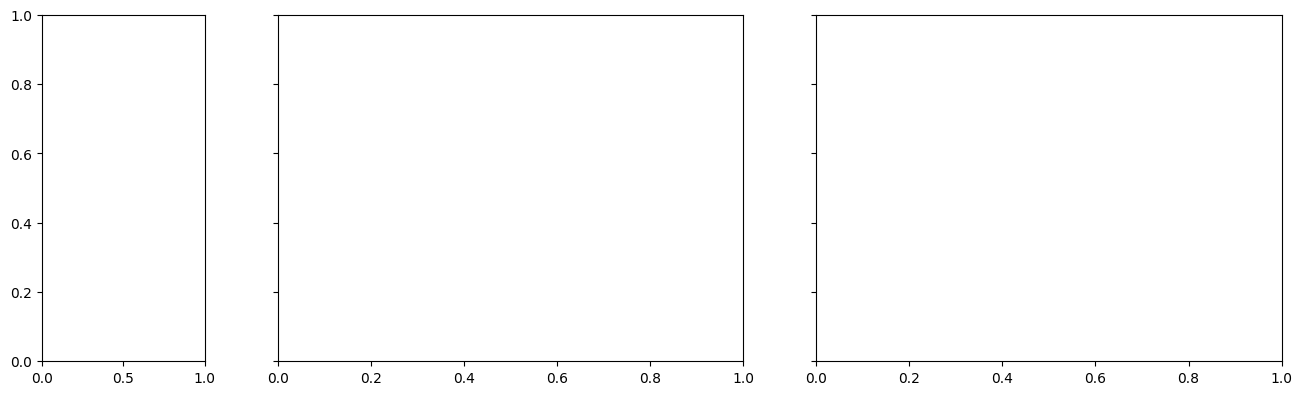

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from utils.utils_ancestral_predict import rolling_mean_std_curve

tax_levels = ["random", "family", "order", "class", "phylum"]
colors = ["#1B4F8A", "#E08A1E", "#8E3B8F"]  # ["tab:blue", "tab:orange", "tab:green"]

fp = 0.1
fn_range = [0.0, 0.3, 0.6]

FONTSIZE = 14

fig, axes = plt.subplots(
    1, 3, figsize=(16, 4.5), sharey=True,
    gridspec_kw={"width_ratios": [0.35, 1, 1]}
)
# ---------------------------------------------------------------
# Corridors (mean ± std of divergence time per taxonomic level),
# drawn ONCE, outside the fn loop
# ---------------------------------------------------------------
tick_pos, tick_lab = [], []
for tax_level in tax_levels:
    t = np.asarray(list(per_split_time[tax_level].values()), dtype=float)
    t = t[t <= 7000]
    mu, sd = t.mean(), t.std()

    for ax in [axes[1], axes[2]]:
        ax.axvspan(mu - sd, mu + sd, color="grey",
                   alpha=0.1, linewidth=0, zorder=0)
        ax.axvline(mu, color="black", linestyle=":",
                   linewidth=1, zorder=1)

    tick_pos.append(mu)
    tick_lab.append(tax_level.capitalize())

# ---------------------------------------------------------------
# Curves
# ---------------------------------------------------------------
for i, fn in enumerate(fn_range):
    all_points_x = []
    all_points_y = []
    all_points_x_noise_rob_mod = []
    all_points_y_noise_rob_mod = []

    for tax_level in tax_levels:
        # orig model
        all_points_x += list(per_split_time[tax_level].values())
        all_points_y += list(mcc_tax_levels_orig_models[tax_level][(fn, fp)]['mcc'])

        # noise-robust model
        n = len(mcc_tax_levels_noise_rob_models[tax_level][(fn, fp)]['mcc'])
        all_points_x_noise_rob_mod += list(per_split_time[tax_level].values())[:n]
        all_points_y_noise_rob_mod += list(mcc_tax_levels_noise_rob_models[tax_level][(fn, fp)]['mcc'])

    # orig model filtered
    x_arr = np.asarray(all_points_x, dtype=float)
    y_arr = np.asarray(all_points_y, dtype=float)
    mask = x_arr <= 7000
    all_points_x = x_arr[mask]
    all_points_y = y_arr[mask]

    # noise-robust model filtered
    x_arr = np.asarray(all_points_x_noise_rob_mod, dtype=float)
    y_arr = np.asarray(all_points_y_noise_rob_mod, dtype=float)
    mask = x_arr <= 7000
    all_points_x_noise_rob_mod = x_arr[mask]
    all_points_y_noise_rob_mod = y_arr[mask]

    x_mean, y_mean, y_std = rolling_mean_std_curve(
        all_points_x, all_points_y, window=1000
    )
    x_mean_nr, y_mean_nr, y_std_nr = rolling_mean_std_curve(
        all_points_x_noise_rob_mod, all_points_y_noise_rob_mod, window=1000
    )

    label = fr"$r_{{FN}} = {fn}$"

    # Left: original models
    axes[1].fill_between(x_mean,
                         np.clip(y_mean - y_std, 0, 1),
                         np.clip(y_mean + y_std, 0, 1),
                         color=colors[i], alpha=0.2, linewidth=0, zorder=2)
    axes[1].plot(x_mean, y_mean, c=colors[i], linestyle="--",
                 linewidth=2, label=label, zorder=3)

    # Right: noise-robust models
    axes[2].fill_between(x_mean_nr,
                         np.clip(y_mean_nr - y_std_nr, 0, 1),
                         np.clip(y_mean_nr + y_std_nr, 0, 1),
                         color=colors[i], alpha=0.2, linewidth=0, zorder=2)
    axes[2].plot(x_mean_nr, y_mean_nr, c=colors[i], linestyle="-",
                 linewidth=2, label=label, zorder=3)


#plt.subplot(1, 3, 2)
cog_remov_add_accuracies_mn_std = {}
cog_remov_add_accuracies_orig_models_mn_std = {}
for rates in cog_remov_add_accuracies.keys():
    cog_remov_add_accuracies_mn_std[rates] = {}
    cog_remov_add_accuracies_orig_models_mn_std[rates] = {}
    for metric in cog_remov_add_accuracies[rates].keys():
        cog_remov_add_accuracies_mn_std[rates][metric] = (np.mean(cog_remov_add_accuracies[rates][metric] ), np.std(cog_remov_add_accuracies[rates][metric] ))
        cog_remov_add_accuracies_orig_models_mn_std[rates][metric] = (np.mean(cog_remov_add_accuracies_orig_models[rates][metric] ), np.std(cog_remov_add_accuracies_orig_models[rates][metric] ))

allowed_fp = {0.0, 0.1, 0.2}

cog_remov_add_accuracies_mn_std_filtered = {
    k: v
    for k, v in cog_remov_add_accuracies_mn_std.items()
    if k[1] in allowed_fp
}

cog_remov_add_accuracies_orig_models_mn_std_filtered = {
    k: v
    for k, v in cog_remov_add_accuracies_orig_models_mn_std.items()
    if k[1] in allowed_fp
}

plot_one_accur_measure(axes[0], "mcc", cog_remov_add_accuracies_mn_std_filtered)
plot_one_accur_measure(axes[0], "mcc", cog_remov_add_accuracies_orig_models_mn_std_filtered, alpha=0.3, fontsize = FONTSIZE)
# axes[2].axhline(y=cog_remov_add_accuracies_orig_models[(0.0, 0.0)]['mcc'][0], color='grey', linestyle='--', linewidth=1.5)
# axes[2].set_ylim([-0.1,1.05])
# axes[2].set_title("MCC", fontsize=FONTSIZE)


# ---------------------------------------------------------------
# Axes styling
# ---------------------------------------------------------------
for ax in [axes[1], axes[2]]:
    # second x-axis layer with taxonomic level names
    sec = ax.secondary_xaxis("top")
    sec.set_xticks(tick_pos)
    sec.set_xticklabels(tick_lab, rotation=50, ha="left")
    sec.tick_params(labelsize=12, length=0)
    sec.spines["top"].set_visible(False)

    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.6)
    ax.tick_params(labelsize=13)
    ax.set_ylim([-0.1, 1.1])
    ax.set_xlabel("Divergence time from nearest \n training relative (Ma)", fontsize=14, labelpad=10)

axes[1].set_title(fr"Original models, $r_{{FP}} = {fp}$", fontsize=14, pad=10)
axes[2].set_title(fr"Noise-robust models, $r_{{FP}} = {fp}$", fontsize=14, pad=10)
axes[0].set_ylabel("MCC", fontsize=14)

axes[0].grid(axis="y", alpha=0.6)
axes[0].set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1])
axes[0].set_title("Phylum level \n train/test splits", fontsize=14, pad=30)
axes[0].set_xlabel(r"$r_{FN}$", fontsize=14, labelpad=10)

# one shared legend instead of one per panel
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3,
           frameon=False, fontsize=13, bbox_to_anchor=(0.5, -0.02))

plt.tight_layout(rect=[0, 0.08, 1, 1])

plt.savefig(
    f"{OUTPUT_DIRECTORY}/plots/noise_in_evo_dist_fp_{fp}_mcc.svg",
    format="svg",
    bbox_inches="tight",
)

plt.savefig(
    f"{OUTPUT_DIRECTORY}/plots/noise_in_evo_dist_fp_{fp}_mcc.pdf",
    format="pdf",
    bbox_inches="tight",
)

plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from utils.utils_ancestral_predict import rolling_mean_std_curve

tax_levels = ["random", "family", "order", "class", "phylum"]
colors = ["#1B4F8A", "#E08A1E", "#8E3B8F"]  # ["tab:blue", "tab:orange", "tab:green"]

fp = 0.1
fn_range = [0.0, 0.3, 0.6]

FONTSIZE = 14

fig, axes = plt.subplots(
    1, 3, figsize=(16, 4.5), sharey=True,
    gridspec_kw={"width_ratios": [0.35, 1, 1]}
)
# ---------------------------------------------------------------
# Corridors (mean ± std of divergence time per taxonomic level),
# drawn ONCE, outside the fn loop
# ---------------------------------------------------------------
tick_pos, tick_lab = [], []
for tax_level in tax_levels:
    t = np.asarray(list(per_split_time[tax_level].values()), dtype=float)
    t = t[t <= 7000]
    mu, sd = t.mean(), t.std()

    for ax in [axes[1], axes[2]]:
        ax.axvspan(mu - sd, mu + sd, color="grey",
                   alpha=0.1, linewidth=0, zorder=0)
        ax.axvline(mu, color="black", linestyle=":",
                   linewidth=1, zorder=1)

    tick_pos.append(mu)
    tick_lab.append(tax_level.capitalize())

# ---------------------------------------------------------------
# Curves
# ---------------------------------------------------------------
for i, fn in enumerate(fn_range):
    all_points_x = []
    all_points_y = []
    all_points_x_noise_rob_mod = []
    all_points_y_noise_rob_mod = []

    for tax_level in tax_levels:
        # orig model
        all_points_x += list(per_split_time[tax_level].values())
        all_points_y += list(mcc_tax_levels_orig_models[tax_level][(fn, fp)]['rmse'])

        # noise-robust model
        n = len(mcc_tax_levels_noise_rob_models[tax_level][(fn, fp)]['rmse'])
        all_points_x_noise_rob_mod += list(per_split_time[tax_level].values())[:n]
        all_points_y_noise_rob_mod += list(mcc_tax_levels_noise_rob_models[tax_level][(fn, fp)]['rmse'])

    # orig model filtered
    x_arr = np.asarray(all_points_x, dtype=float)
    y_arr = np.asarray(all_points_y, dtype=float)
    mask = x_arr <= 7000
    all_points_x = x_arr[mask]
    all_points_y = y_arr[mask]

    # noise-robust model filtered
    x_arr = np.asarray(all_points_x_noise_rob_mod, dtype=float)
    y_arr = np.asarray(all_points_y_noise_rob_mod, dtype=float)
    mask = x_arr <= 7000
    all_points_x_noise_rob_mod = x_arr[mask]
    all_points_y_noise_rob_mod = y_arr[mask]

    x_mean, y_mean, y_std = rolling_mean_std_curve(
        all_points_x, all_points_y, window=1000
    )
    x_mean_nr, y_mean_nr, y_std_nr = rolling_mean_std_curve(
        all_points_x_noise_rob_mod, all_points_y_noise_rob_mod, window=1000
    )

    label = fr"$r_{{FN}} = {fn}$"

    # Left: original models
    axes[1].fill_between(x_mean,
                         np.clip(y_mean - y_std, 0, 30),
                         np.clip(y_mean + y_std, 0, 30),
                         color=colors[i], alpha=0.2, linewidth=0, zorder=2)
    axes[1].plot(x_mean, y_mean, c=colors[i], linestyle="--",
                 linewidth=2, label=label, zorder=3)

    # Right: noise-robust models
    axes[2].fill_between(x_mean_nr,
                         np.clip(y_mean_nr - y_std_nr, 0, 30),
                         np.clip(y_mean_nr + y_std_nr, 0, 30),
                         color=colors[i], alpha=0.2, linewidth=0, zorder=2)
    axes[2].plot(x_mean_nr, y_mean_nr, c=colors[i], linestyle="-",
                 linewidth=2, label=label, zorder=3)


#plt.subplot(1, 3, 2)
cog_remov_add_accuracies_mn_std = {}
cog_remov_add_accuracies_orig_models_mn_std = {}
for rates in cog_remov_add_accuracies.keys():
    cog_remov_add_accuracies_mn_std[rates] = {}
    cog_remov_add_accuracies_orig_models_mn_std[rates] = {}
    for metric in cog_remov_add_accuracies[rates].keys():
        cog_remov_add_accuracies_mn_std[rates][metric] = (np.mean(cog_remov_add_accuracies[rates][metric] ), np.std(cog_remov_add_accuracies[rates][metric] ))
        cog_remov_add_accuracies_orig_models_mn_std[rates][metric] = (np.mean(cog_remov_add_accuracies_orig_models[rates][metric] ), np.std(cog_remov_add_accuracies_orig_models[rates][metric] ))

allowed_fp = {0.0, 0.1, 0.2}

cog_remov_add_accuracies_mn_std_filtered = {
    k: v
    for k, v in cog_remov_add_accuracies_mn_std.items()
    if k[1] in allowed_fp
}

cog_remov_add_accuracies_orig_models_mn_std_filtered = {
    k: v
    for k, v in cog_remov_add_accuracies_orig_models_mn_std.items()
    if k[1] in allowed_fp
}

plot_one_accur_measure(axes[0], "rmse", cog_remov_add_accuracies_mn_std_filtered)
plot_one_accur_measure(axes[0], "rmse", cog_remov_add_accuracies_orig_models_mn_std_filtered, alpha=0.3, fontsize = FONTSIZE)
# axes[2].axhline(y=cog_remov_add_accuracies_orig_models[(0.0, 0.0)]['mcc'][0], color='grey', linestyle='--', linewidth=1.5)
# axes[2].set_ylim([-0.1,1.05])
# axes[2].set_title("MCC", fontsize=FONTSIZE)


# ---------------------------------------------------------------
# Axes styling
# ---------------------------------------------------------------
for ax in [axes[1], axes[2]]:
    # second x-axis layer with taxonomic level names
    sec = ax.secondary_xaxis("top")
    sec.set_xticks(tick_pos)
    sec.set_xticklabels(tick_lab, rotation=50, ha="left")
    sec.tick_params(labelsize=12, length=0)
    sec.spines["top"].set_visible(False)

    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.6)
    ax.tick_params(labelsize=13)
    #ax.set_ylim([-0.1, 1.1])
    ax.set_xlabel("Divergence time from nearest \n training relative (Ma)", fontsize=14, labelpad=10)

axes[1].set_title(fr"Original models, $r_{{FP}} = {fp}$", fontsize=14, pad=10)
axes[2].set_title(fr"Noise-robust models, $r_{{FP}} = {fp}$", fontsize=14, pad=10)
axes[0].set_ylabel("RMSE (degrees)", fontsize=14)

axes[0].grid(axis="y", alpha=0.6)
axes[0].set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1])
axes[0].set_title("Phylum level \n train/test splits", fontsize=14, pad=30)
axes[0].set_xlabel(r"$r_{FN}$", fontsize=14, labelpad=10)

# one shared legend instead of one per panel
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3,
           frameon=False, fontsize=13, bbox_to_anchor=(0.5, -0.02))

plt.tight_layout(rect=[0, 0.08, 1, 1])

plt.savefig(
    f"{OUTPUT_DIRECTORY}/plots/noise_in_evo_dist_fp_{fp}_rmse.svg",
    format="svg",
    bbox_inches="tight",
)

plt.savefig(
    f"{OUTPUT_DIRECTORY}/plots/noise_in_evo_dist_fp_{fp}_rmse.pdf",
    format="pdf",
    bbox_inches="tight",
)

plt.show()

In [31]:
print("Original y:")
print("  std:", np.std(all_points_y))
print("  min:", np.min(all_points_y))
print("  max:", np.max(all_points_y))

mean_x, mean_y, std_y = rolling_mean_std_curve(
    all_points_x, all_points_y, window=1000
)

print("Rolling std:")
print("  min:", np.min(std_y))
print("  median:", np.median(std_y))
print("  max:", np.max(std_y))

Original y:
  std: 2.4619635555751764
  min: 9.354474601406505
  max: 23.881739119647595
Rolling std:
  min: 0.4435917672543601
  median: 1.7770152998067414
  max: 4.1167791507657


### 4.  Ancestral phenotype prediction

#### 4.1  ML predictions

In [6]:
# Read the annotated count table and get the list of COGs from there
ogt_cogs = pd.read_csv("../data_ogt/ogt_cog.csv", sep=",")
X_column_names = ogt_cogs.columns[ogt_cogs.columns.str.startswith("COG")].tolist()

In [7]:
# Read the GTDB tables for the genome taxonomy

import polars as pl

BAC_TSV = '../data_preparation/gtdb_files/bac120_metadata_r202.tsv'
ARC_TSV = '../data_preparation/gtdb_files/ar122_metadata_r202.tsv'

tax_level = "phylum"
tax_levels = {"domain": 0, "phylum": 1, "class": 2, "order": 3, "family": 4}

gtdb_df = pl.concat([pl.read_csv(BAC_TSV, separator="\t"),
    pl.read_csv(ARC_TSV, separator="\t")])
gtdb_df = gtdb_df[['accession', "gtdb_taxonomy"]]
for key in tax_levels.keys():
    tax_level = tax_levels[key]
    gtdb_df = gtdb_df.with_columns(pl.col("gtdb_taxonomy").str.split(';').list.get(tax_levels[key]).alias(key))
gtdb_df = gtdb_df.drop("gtdb_taxonomy")
gtdb_df = gtdb_df.to_pandas()
gtdb_df

,accession,domain,phylum,class,order,family
0,GB_GCA_000013845.2,d__Bacteria,p__Firmicutes_A,c__Clostridia,o__Clostridiales,f__Clostridiaceae
1,GB_GCA_000016465.1,d__Bacteria,p__Proteobacteria,c__Gammaproteobacteria,o__Enterobacterales,f__Pasteurellaceae
2,GB_GCA_000024525.1,d__Bacteria,p__Bacteroidota,c__Bacteroidia,o__Cytophagales,f__Spirosomaceae
3,GB_GCA_000152525.1,d__Bacteria,p__Proteobacteria,c__Gammaproteobacteria,o__Pseudomonadales,f__Pseudomonadaceae
4,GB_GCA_000172955.1,d__Bacteria,p__Campylobacterota,c__Campylobacteria,o__Campylobacterales,f__Helicobacteraceae
...,...,...,...,...,...,...
258401,RS_GCF_900109065.1,d__Archaea,p__Halobacteriota,c__Halobacteria,o__Halobacteriales,f__Haloferacaceae
258402,RS_GCF_900114585.1,d__Archaea,p__Methanobacteriota,c__Methanobacteria,o__Methanobacteriales,f__Methanobacteriaceae
258403,RS_GCF_900773915.1,d__Archaea,p__Halobacteriota,c__Methanosarcinia,o__Methanosarcinales,f__Methanosarcinaceae
258404,RS_GCF_902384055.1,d__Archaea,p__Methanobacteriota,c__Methanobacteria,o__Methanobacteriales,f__Methanobacteriaceae


In [8]:
# Get the species tree leaf node names
leaves_acc_names = pd.read_csv("../ancestral_data/GenomesInfo.csv", sep=",")
columns_to_keep = ['accession', 'ShortCode']
leaves_acc_names = leaves_acc_names[columns_to_keep]
leaves_acc_names

,accession,ShortCode
0,GB_GCA_003599535.1,AABM5X1
1,GB_GCA_005223185.1,AABM5X2
2,GB_GCA_002127415.1,AABM5X3
3,GB_GCA_003598085.1,Abys1
4,GB_GCA_003223555.1,Acid1
...,...,...
1002,GB_GCA_001775395.1,Zixi1
1003,GB_GCA_002791595.1,Zixi2
1004,GB_GCA_003105265.1,Zixi3
1005,GB_GCA_002838945.1,Zixi4


In [9]:
leave_nodes_with_taxonomy = pd.merge(leaves_acc_names, gtdb_df, on="accession", how="inner")
leave_nodes_with_taxonomy

,accession,ShortCode,domain,phylum,class,order,family
0,GB_GCA_003599535.1,AABM5X1,d__Bacteria,p__AABM5-125-24,c__B3-LCP,o__B3-LCP,f__B3-LCP
1,GB_GCA_005223185.1,AABM5X2,d__Bacteria,p__AABM5-125-24,c__B3-LCP,o__B3-LCP,f__B3-LCP
2,GB_GCA_002127415.1,AABM5X3,d__Bacteria,p__AABM5-125-24,c__AABM5-125-24,o__AABM5-125-24,f__AABM5-125-24
3,GB_GCA_003598085.1,Abys1,d__Bacteria,p__Abyssubacteria,c__SURF-5,o__SURF-5,f__SURF-5
4,GB_GCA_003223555.1,Acid1,d__Bacteria,p__Acidobacteriota,c__Vicinamibacteria,o__Fen-336,f__Fen-336
...,...,...,...,...,...,...,...
992,GB_GCA_001775395.1,Zixi1,d__Bacteria,p__Zixibacteria,c__MSB-5A5,o__UBA10806,f__UBA10806
993,GB_GCA_002791595.1,Zixi2,d__Bacteria,p__Zixibacteria,c__MSB-5A5,o__UM-FILTER-46-8,f__UM-FILTER-46-8
994,GB_GCA_003105265.1,Zixi3,d__Bacteria,p__Zixibacteria,c__MSB-5A5,o__GN15,f__FEB-12
995,GB_GCA_002838945.1,Zixi4,d__Bacteria,p__Zixibacteria,c__MSB-5A5,o__GN15,f__PGXB01


In [10]:
# Read the tree file and pivot it into a COG count table

df = pd.read_csv('../ancestral_data/TableAncestralRoot1_aggregated_byCOG.tsv', sep='\t', dtype={'column_name': str})
df = df.T

df.columns = df.loc['COG']
df = df.drop(index='COG')
df.columns.name = None

pivot_df = df.apply(pd.to_numeric)
pivot_df.index = pivot_df.index.str.replace(r'\(\d+\)$', '', regex=True)

node_names = pivot_df.index.tolist()
pivot_df

,COG0001,COG0002,COG0003,COG0004,COG0005,COG0006,COG0007,COG0008,COG0010,COG0012,...,COG5611,COG5615,COG5621,COG5625,COG5632,COG5640,COG5643,COG5650,COG5652,COG5663
AABM5X1,1.00,0.00,0.00,0.00,0.00,0.00,1.00,1.00,1.00,1.00,...,0.00,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.00,0.0
AABM5X2,1.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,1.00,...,0.00,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.00,0.0
AABM5X3,0.00,0.00,1.00,0.00,0.00,0.00,0.00,1.00,1.00,1.00,...,0.00,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.00,0.0
Abys1,1.00,1.00,1.00,1.00,1.00,0.00,0.00,1.00,1.00,1.00,...,0.00,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.00,0.0
Acid1,1.00,1.00,1.00,1.00,1.00,1.00,0.00,1.00,0.00,1.00,...,0.00,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.00,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2008,0.55,0.58,0.76,0.37,1.00,0.01,0.12,1.00,1.00,0.23,...,0.01,0.0,0.01,0.0,0.00,0.0,0.0,0.0,0.01,0.0
2009,0.26,0.38,0.09,0.31,0.91,0.00,0.24,0.68,0.08,1.00,...,0.02,0.0,0.00,0.0,0.02,0.0,0.0,0.0,0.09,0.0
2010,0.24,0.51,0.91,0.13,0.70,0.00,0.06,1.00,0.68,0.15,...,0.01,0.0,0.03,0.0,0.00,0.0,0.0,0.0,0.01,0.0
2011,0.08,0.07,0.14,0.08,0.29,0.00,0.05,0.88,0.23,0.13,...,0.00,0.0,0.01,0.0,0.00,0.0,0.0,0.0,0.00,0.0


In [11]:
# Optionally: threshold the COG count values to convert them to 0/1s
threshold = 0.04
pivot_df = pivot_df.applymap(lambda x: 0 if x <= threshold else max(x, 1))
pivot_df

/scratch/ipykernel_1547598/2279624814.py:3: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  pivot_df = pivot_df.applymap(lambda x: 0 if x <= threshold else max(x, 1))


,COG0001,COG0002,COG0003,COG0004,COG0005,COG0006,COG0007,COG0008,COG0010,COG0012,...,COG5611,COG5615,COG5621,COG5625,COG5632,COG5640,COG5643,COG5650,COG5652,COG5663
AABM5X1,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
AABM5X2,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
AABM5X3,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Abys1,1.0,1.0,1.0,1.0,1.0,0.0,0.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Acid1,1.0,1.0,1.0,1.0,1.0,1.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2008,1.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2009,1.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2010,1.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2011,1.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [12]:
# Find COGs that are in the intersection between the COG set from the species tree and the COGs from the annotated data

cogs_from_mastertable = list(pivot_df.columns)
cogs_intersect = list(set(cogs_from_mastertable) & set(X_column_names))
cogs_intersect = sorted(cogs_intersect, key=lambda x: int(x[3:]))

# Apply the intersection COGs to the species tree count table
tree_nodes_data = pivot_df[cogs_intersect]
tree_nodes_data

,COG0001,COG0002,COG0003,COG0004,COG0005,COG0006,COG0007,COG0008,COG0010,COG0012,...,COG5611,COG5615,COG5621,COG5625,COG5632,COG5640,COG5643,COG5650,COG5652,COG5663
AABM5X1,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
AABM5X2,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
AABM5X3,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Abys1,1.0,1.0,1.0,1.0,1.0,0.0,0.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Acid1,1.0,1.0,1.0,1.0,1.0,1.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2008,1.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2009,1.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2010,1.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2011,1.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [13]:
# Prepare model train data
ogt_annot = pd.read_csv("../data_ogt/ogt_cog_annot.csv", sep=",")
merged_tab  = pd.merge(ogt_cogs, ogt_annot, on="accession", how="inner") 
merged_tab["ogt_binary"] = np.where(merged_tab["ogt"] > OGT_BOUNDARY, "high", "low")

merged_tab

,accession,COG0001,COG0002,COG0003,COG0004,COG0005,COG0006,COG0007,COG0008,COG0009,...,COG5658,COG5659,COG5660,COG5661,COG5662,COG5663,COG5664,COG5665,ogt,ogt_binary
0,GB_GCA_000010565.1,1,1,0,1,2,1,1,2,1,...,1,0,0,0,2,1,0,0,55.0,high
1,GB_GCA_000016605.1,1,1,0,3,1,2,2,2,1,...,0,0,0,0,0,0,0,0,75.0,high
2,GB_GCA_000143165.1,1,1,1,1,1,1,1,1,1,...,1,0,0,0,0,0,0,0,31.0,low
3,GB_GCA_000145985.1,1,1,0,0,0,2,0,2,1,...,0,0,0,0,0,0,0,0,93.5,high
4,GB_GCA_000161775.1,1,1,0,2,1,6,3,3,1,...,0,0,0,0,0,0,0,0,45.0,low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3672,RS_GCF_904846415.1,1,1,1,2,1,1,1,3,2,...,0,0,0,0,0,0,0,0,25.0,low
3673,RS_GCF_904846695.1,1,1,1,1,1,1,2,3,2,...,0,0,0,0,0,0,0,0,19.0,low
3674,RS_GCF_904846715.1,1,1,1,1,1,1,2,3,2,...,0,0,0,0,0,0,0,0,22.0,low
3675,RS_GCF_905220995.1,1,1,0,1,1,2,2,2,2,...,0,0,1,0,1,0,0,0,30.0,low


In [14]:
# Prepare phenotype annotation vector

y_label_train_class = torch.tensor(merged_tab["ogt_binary"].map({"high": 1, "low": 0}).to_numpy(), dtype=torch.long)
y_label_train_regr = torch.tensor(merged_tab["ogt"].to_numpy(), dtype=torch.long)
numeric_df = merged_tab.iloc[:, 1:-2]
numeric_values = torch.tensor(numeric_df.values, dtype=torch.float32)
numeric_values = (numeric_values> 0).int()  

X_column_names = merged_tab.columns.tolist()[1:-1]
name_to_idx = {name: i for i, name in enumerate(X_column_names)}

# Keep only those in cogs_intersect AND present in X_column_names
cogs_intersect = list(set(cogs_from_mastertable) & set(X_column_names))
cogs_intersect = sorted(cogs_intersect, key=lambda x: int(x[3:]))
keep_indices = [name_to_idx[cog] for cog in cogs_intersect if cog in name_to_idx]

# Filter tensor and column names
X_val_train_filtered = numeric_values[:, keep_indices]
X_column_names_filtered = [X_column_names[i] for i in keep_indices]
X_val_train_filtered.shape

torch.Size([3677, 2848])

In [15]:
# Initialize XGBoost for training

from sklearn.pipeline import make_pipeline

In [16]:
from utils.utils_ancestral_predict import augment_data_with_noise

# Augment X train with the noise 
x_noisy_samples = 100
fp_rate_mean = 0.1
fn_rate_mean = 1.0
noise_type = "exp"

X_augmented, y_augmented = augment_data_with_noise(X_val_train_filtered, y_label_train_regr, x_noisy_samples, fp_rate_mean, fn_rate_mean, noise_type=noise_type)#, filename=None)
X_augmented.shape

torch.Size([371377, 2848])

In [17]:
from tqdm import tqdm

from sklearn.utils.class_weight import compute_class_weight
from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()

from utils.utils_ancestral_predict import label_ogt_range

In [18]:
# Train a model on noise augmented data

pipe_with_noise = make_pipeline(make_xgb())

range_labels = label_ogt_range(y_augmented)
le = LabelEncoder()
range_ids = le.fit_transform(range_labels)  # Converts to 0,1,2
label_to_int = {'low': 0, 'high': 1}
range_ids = np.vectorize(label_to_int.get)(range_labels)

classes = np.unique(range_ids)
weights = compute_class_weight(class_weight='balanced', classes=classes, y=range_ids)
class_weights = dict(zip(classes, weights))
sample_weights = np.array([class_weights[c] for c in range_ids])


# Convert to numpy
X_train_np = X_augmented.cpu().numpy()
y_train_np = y_augmented.cpu().numpy().flatten()

sample_weights_np = sample_weights if isinstance(sample_weights, np.ndarray) else sample_weights.cpu().numpy()
range_ids_np = range_ids if isinstance(range_ids, np.ndarray) else range_ids.cpu().numpy()

# 1. Gating model
classifier = make_xgb()
classifier.fit(X_augmented, range_ids, sample_weight=sample_weights)

# Right and left regressors
temp_bound = OGT_BOUNDARY
low_mask = y_train_np < temp_bound
high_mask = y_train_np >= temp_bound

model_low = make_xgb_regressor()
model_high = make_xgb_regressor()
model_low.fit(X_train_np[low_mask], y_train_np[low_mask])
model_high.fit(X_train_np[high_mask], y_train_np[high_mask])

# Lower bound regressors (e.g. 10th percentile)
model_low_q10 = make_xgb_quantile_regressor(0.1)
model_high_q10 = make_xgb_quantile_regressor(0.1)

# Upper bound regressors (e.g. 90th percentile)
model_low_q90 = make_xgb_quantile_regressor(0.9)
model_high_q90 = make_xgb_quantile_regressor(0.9)

model_low_q10.fit(X_train_np[low_mask], y_train_np[low_mask])
model_low_q90.fit(X_train_np[low_mask], y_train_np[low_mask])

model_high_q10.fit(X_train_np[high_mask], y_train_np[high_mask])
model_high_q90.fit(X_train_np[high_mask], y_train_np[high_mask])

,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'reg:quantileerror'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.7
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import

In [19]:
import joblib

filename = f"apply_to_tree_trained_models_fp_{fp_rate_mean}_fn_{fn_rate_mean}_noise_type_{noise_type}_x_{x_noisy_samples}.pkl"
joblib.dump((pipe_with_noise, model_low, model_high), f"{OUTPUT_DIRECTORY}/{TRAINED_MOD_DIR}/{filename}")

['../data_ogt/outputs/COG_aa/phylum/trained_models_train_val_test/apply_to_tree_trained_models_fp_0.1_fn_1.0_noise_type_exp_x_100.pkl']

In [20]:
# Convert tree genomes to a tensor
numeric_df = tree_nodes_data.select_dtypes(include=["number"])
ancestral_nodes_tensor = torch.tensor(numeric_df.to_numpy())

# Apply the trained model to the tree genomes
y_pred_ancestr_nodes_gating = classifier.predict(ancestral_nodes_tensor.cpu())

# Predict the probabilities of each class and find the maximum probability
y_proba_ancestr_nodes_gating = classifier.predict_proba(ancestral_nodes_tensor.cpu())
max_proba_gating = [max(x) for x in y_proba_ancestr_nodes_gating]

# tree_nodes_data = pivot_df[cogs_intersect]
# tree_nodes_data

# Calculale the final prediction of the gating model
pred_low = model_low.predict(ancestral_nodes_tensor.cpu())
pred_high = model_high.predict(ancestral_nodes_tensor.cpu())
y_pred_ancestr_nodes_final = y_proba_ancestr_nodes_gating[:, 0] * pred_low + y_proba_ancestr_nodes_gating[:, 1] * pred_high

In [21]:
# Find the uncertanty related statistics

# gating probabilities
p_low = y_proba_ancestr_nodes_gating[:, 0]
p_high = y_proba_ancestr_nodes_gating[:, 1]

# mean predictions
pred_low_point  = model_low.predict(ancestral_nodes_tensor.cpu())
pred_high_point = model_high.predict(ancestral_nodes_tensor.cpu())

# quantile predictions
pred_low_q10  = model_low_q10.predict(ancestral_nodes_tensor.cpu())
pred_low_q90  = model_low_q90.predict(ancestral_nodes_tensor.cpu())
pred_high_q10 = model_high_q10.predict(ancestral_nodes_tensor.cpu())
pred_high_q90 = model_high_q90.predict(ancestral_nodes_tensor.cpu())

# final mixture quantiles
final_lower = p_low * pred_low_q10 + p_high * pred_high_q10
final_upper = p_low * pred_low_q90 + p_high * pred_high_q90

# interval width per node
interval_width = final_upper - final_lower

# combined variance per node (law of total variance)
sigma1_sq = ((pred_low_q90  - pred_low_q10)  / (2 * 1.28)) ** 2
sigma2_sq = ((pred_high_q90 - pred_high_q10) / (2 * 1.28)) ** 2
reg_unc   = p_low * sigma1_sq + p_high * sigma2_sq
gate_unc  = p_low * p_high * (pred_low_point - pred_high_point) ** 2
combined_var = reg_unc + gate_unc

In [22]:
# Generate a table with all genome names from the species tree and the model predictions

# Count for the correctly predicted extant genomes (the ones whose true annotations we know)
correct = 0
total = 0

# Arrays for storing the values for each tree node 
annot_vs_pred_label = []
ogt_gating_arr = []
ogt_final_arr = []
interval_width_arr = []
error = []
final_lower_arr, final_upper_arr, interval_width_arr, combined_var_arr = [], [], [], []

tree_node_names_list = tree_nodes_data.index.tolist()
merged_df = pd.merge(ogt_annot, leaves_acc_names, on="accession", how="left")

# Iterate over all nodes in the species tree 
for idx, node in enumerate(tree_node_names_list):
    final_lower_arr.append(final_lower[idx])
    final_upper_arr.append(final_upper[idx])
    interval_width_arr.append(interval_width[idx])
    combined_var_arr.append(combined_var[idx])

    if node in list(merged_df['ShortCode']):
        
        ogt = merged_df.loc[merged_df["ShortCode"] == node, "ogt"]
        ogt_gating_arr.append("high" if ogt.iloc[0]> OGT_BOUNDARY else "low")
        ogt_final_arr.append(ogt.iloc[0])
        annot_vs_pred_label.append("annot")

        # Count the number or correctly predicted extant genomes
        if (ogt.iloc[0] > OGT_BOUNDARY and y_pred_ancestr_nodes_gating[idx] == 1) or (ogt.iloc[0] < OGT_BOUNDARY and y_pred_ancestr_nodes_gating[idx] == 0):
            correct += 1
        total +=1   
        error.append((ogt.iloc[0] - y_pred_ancestr_nodes_final[idx])**2)
    else:
        annot_vs_pred_label.append("predict")
        ogt_gating_arr.append("high" if y_pred_ancestr_nodes_gating[idx] == 1 else "low")  #{'low': 0, 'high': 1}
        ogt_final_arr.append(y_pred_ancestr_nodes_final[idx])

# Generate the final table
df_pred = pd.DataFrame({
    'NodeName': tree_node_names_list,
    'ogt_gating': ogt_gating_arr,
    'ogt_final': ogt_final_arr,
    'annot_or_predict':annot_vs_pred_label,
    'max_proba_gating': max_proba_gating,
    "proba_and_uncert": y_proba_ancestr_nodes_gating[:, 1],
    'final_lower':       final_lower_arr,
    'final_upper':       final_upper_arr,
    'interval_width':    interval_width_arr,
    'combined_var':      combined_var_arr,
})

print(f"Correct predict = {correct} of {total}; which is {correct/total}; RMSE = {np.sqrt(np.mean(error))}")
print(f"min pred temp = {np.min(ogt_final_arr)}; max pred temp = {np.max(ogt_final_arr)}")
df_pred


Correct predict = 144 of 161; which is 0.8944099378881988; RMSE = 6.011766125841915
min pred temp = 16.5; max pred temp = 79.62195587158203


,NodeName,ogt_gating,ogt_final,annot_or_predict,max_proba_gating,proba_and_uncert,final_lower,final_upper,interval_width,combined_var
0,AABM5X1,high,53.144878,predict,0.859793,0.859793,46.541882,59.635944,13.094063,87.680641
1,AABM5X2,high,54.313145,predict,0.954202,0.954202,48.908089,59.680492,10.772404,35.515495
2,AABM5X3,high,58.152084,predict,0.980869,0.980869,50.865631,62.875172,12.009541,31.988165
3,Abys1,high,53.587185,predict,0.922841,0.922841,49.943504,60.846786,10.903282,42.750973
4,Acid1,high,42.328014,predict,0.509670,0.509670,38.174309,47.763390,9.589081,134.768082
...,...,...,...,...,...,...,...,...,...,...
2008,2008,high,53.540863,predict,0.981440,0.981440,51.568359,61.766445,10.198086,21.889730
2009,2009,high,54.116688,predict,0.985937,0.985937,53.183113,59.884090,6.700977,10.350422
2010,2010,high,60.437435,predict,0.995851,0.995851,56.362896,66.947021,10.584126,19.668253
2011,2011,high,53.676418,predict,0.949445,0.949445,50.173244,60.887569,10.714325,34.585499


In [23]:
# Print the prediction results for the root node
df_pred.loc[df_pred["NodeName"] == "2012"]

,NodeName,ogt_gating,ogt_final,annot_or_predict,max_proba_gating,proba_and_uncert,final_lower,final_upper,interval_width,combined_var
2012,2012,high,59.927979,predict,0.853811,0.853811,45.928761,74.468071,28.53931,263.88736


#### 4.2.  Wagner predictions

In [24]:
from Bio import Phylo

# Read the already existing tree file that we annotate with the model predictions below 
tree = Phylo.read("../ancestral_data/C65.tree", "newick")

In [25]:
merged_tab

,accession,COG0001,COG0002,COG0003,COG0004,COG0005,COG0006,COG0007,COG0008,COG0009,...,COG5658,COG5659,COG5660,COG5661,COG5662,COG5663,COG5664,COG5665,ogt,ogt_binary
0,GB_GCA_000010565.1,1,1,0,1,2,1,1,2,1,...,1,0,0,0,2,1,0,0,55.0,high
1,GB_GCA_000016605.1,1,1,0,3,1,2,2,2,1,...,0,0,0,0,0,0,0,0,75.0,high
2,GB_GCA_000143165.1,1,1,1,1,1,1,1,1,1,...,1,0,0,0,0,0,0,0,31.0,low
3,GB_GCA_000145985.1,1,1,0,0,0,2,0,2,1,...,0,0,0,0,0,0,0,0,93.5,high
4,GB_GCA_000161775.1,1,1,0,2,1,6,3,3,1,...,0,0,0,0,0,0,0,0,45.0,low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3672,RS_GCF_904846415.1,1,1,1,2,1,1,1,3,2,...,0,0,0,0,0,0,0,0,25.0,low
3673,RS_GCF_904846695.1,1,1,1,1,1,1,2,3,2,...,0,0,0,0,0,0,0,0,19.0,low
3674,RS_GCF_904846715.1,1,1,1,1,1,1,2,3,2,...,0,0,0,0,0,0,0,0,22.0,low
3675,RS_GCF_905220995.1,1,1,0,1,1,2,2,2,2,...,0,0,1,0,1,0,0,0,30.0,low


In [26]:
phenotype_col = "ogt_binary"

# Map phenotype names to states
phenotype_map = {
    "low": 0,
    "high": 1
}

# Create accession -> phenotype dictionary
phenotype_dict = (
    merged_tab
    .set_index("accession")[phenotype_col]
    .map(phenotype_map)
    .dropna()
    .to_dict()
)

In [27]:
# accession -> tree leaf name
accession_to_leaf = (
    leaves_acc_names
    .set_index("accession")["ShortCode"]
    .to_dict()
)

leaf_phenotype_dict = {
    accession_to_leaf[accession]: phenotype
    for accession, phenotype in phenotype_dict.items()
    if accession in accession_to_leaf
}



In [28]:
tree_leaves = {leaf.name for leaf in tree.get_terminals()}

matched = set(leaf_phenotype_dict) & tree_leaves
not_in_tree = set(leaf_phenotype_dict) - tree_leaves

print("Phenotype annotations:", len(phenotype_dict))
print("Mapped to tree names:", len(leaf_phenotype_dict))
print("Found in tree:", len(matched))
print("Not found in tree:", len(not_in_tree))

print("Examples not found:", list(not_in_tree)[:10])

Phenotype annotations: 3677
Mapped to tree names: 161
Found in tree: 161
Not found in tree: 0
Examples not found: []


In [29]:
import copy

pruned_tree = copy.deepcopy(tree)

for leaf in pruned_tree.get_terminals():
    if leaf.name not in leaf_phenotype_dict:
        pruned_tree.prune(leaf)

print("Original leaves:", len(tree.get_terminals()))
print("Pruned leaves:", len(pruned_tree.get_terminals()))

Original leaves: 1007
Pruned leaves: 161


In [30]:
all_nodes = pruned_tree.find_clades()

In [31]:
from utils.utils_ancestral_predict import wagner_reconstruction

state_labels = {
    0: "low",
    1: "high"
}

(
    node_annotations,
    node_confidence,
    node_probabilities,
    scores,
    parsimony_score
) = wagner_reconstruction(
    pruned_tree,
    leaf_phenotype_dict,
    state_labels=state_labels
)

parsimony_score

36.0

In [32]:
def get_node_id(node):
    if node.name is not None:
        return str(node.name)
    elif node.confidence is not None:
        return str(node.confidence)
    else:
        return None

In [33]:
print("annotations:", len(node_annotations))
print("confidence:", len(node_confidence))
print("probabilities:", len(node_probabilities))
print("scores:", len(scores))
print("parsimony:", parsimony_score)

annotations: 321
confidence: 321
probabilities: 321
scores: 321
parsimony: 36.0


In [34]:
all_nodes = list(pruned_tree.find_clades())

wagner_annotation = {
    get_node_id(node): node_annotations[node]
    for node in all_nodes
    if get_node_id(node) is not None
}

wagner_confidence = {
    get_node_id(node): node_confidence[node]
    for node in all_nodes
    if get_node_id(node) is not None
}

wagner_diderm_proba = {
    get_node_id(node): node_probabilities[node][0]
    for node in all_nodes
    if get_node_id(node) is not None
}

wagner_monoderm_proba = {
    get_node_id(node): node_probabilities[node][1]
    for node in all_nodes
    if get_node_id(node) is not None
}


In [35]:
df_pred["wagner_annotation_binary"] = (
    df_pred["NodeName"].astype(str).map(wagner_annotation)
)

df_pred["wagner_confidence_binary"] = (
    df_pred["NodeName"].astype(str).map(wagner_confidence)
)

df_pred["wagner_mesoph_proba"] = (
    df_pred["NodeName"].astype(str).map(wagner_diderm_proba)
)

df_pred["wagner_thermoph_proba"] = (
    df_pred["NodeName"].astype(str).map(wagner_monoderm_proba)
)

In [36]:
df_pred

,NodeName,ogt_gating,ogt_final,annot_or_predict,max_proba_gating,proba_and_uncert,final_lower,final_upper,interval_width,combined_var,wagner_annotation_binary,wagner_confidence_binary,wagner_mesoph_proba,wagner_thermoph_proba
0,AABM5X1,high,53.144878,predict,0.859793,0.859793,46.541882,59.635944,13.094063,87.680641,NaN,NaN,NaN,NaN
1,AABM5X2,high,54.313145,predict,0.954202,0.954202,48.908089,59.680492,10.772404,35.515495,NaN,NaN,NaN,NaN
2,AABM5X3,high,58.152084,predict,0.980869,0.980869,50.865631,62.875172,12.009541,31.988165,NaN,NaN,NaN,NaN
3,Abys1,high,53.587185,predict,0.922841,0.922841,49.943504,60.846786,10.903282,42.750973,NaN,NaN,NaN,NaN
4,Acid1,high,42.328014,predict,0.509670,0.509670,38.174309,47.763390,9.589081,134.768082,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2008,2008,high,53.540863,predict,0.981440,0.981440,51.568359,61.766445,10.198086,21.889730,high,0.731059,0.268941,0.731059
2009,2009,high,54.116688,predict,0.985937,0.985937,53.183113,59.884090,6.700977,10.350422,low,0.880797,0.880797,0.119203
2010,2010,high,60.437435,predict,0.995851,0.995851,56.362896,66.947021,10.584126,19.668253,high,0.880797,0.119203,0.880797
2011,2011,high,53.676418,predict,0.949445,0.949445,50.173244,60.887569,10.714325,34.585499,NaN,NaN,NaN,NaN


In [37]:
from utils.utils_ancestral_predict import wagner_reconstruction_continuous


In [38]:
leaf_value_dict = (
    merged_tab
    .set_index("accession")["ogt"]
    .dropna()
    .to_dict()
)


leaf_values = {
    accession_to_leaf[accession]: float(value)
    for accession, value in leaf_value_dict.items()
    if accession in accession_to_leaf
}


In [39]:
(
    node_annotations,
    scores,
    parsimony_score,
    intervals
) = wagner_reconstruction_continuous(
    pruned_tree,
    leaf_values,
)

In [41]:
#intervals

In [42]:
# Map tree nodes -> reconstructed continuous Wagner value
wagner_values = {
    get_node_id(node): value
    for node, value in node_annotations.items()
    if get_node_id(node) is not None
}

# Add Wagner predictions to df_pred
df_pred["wagner_prediction_ogt"] = (
    df_pred["NodeName"].map(wagner_values)
)

In [43]:
wagner_lower = {
    get_node_id(node): interval[0]
    for node, interval in intervals.items()
    if get_node_id(node) is not None
}

wagner_upper = {
    get_node_id(node): interval[1]
    for node, interval in intervals.items()
    if get_node_id(node) is not None
}

In [44]:
df_pred["wagner_lower"] = df_pred["NodeName"].map(wagner_lower)
df_pred["wagner_upper"] = df_pred["NodeName"].map(wagner_upper)
df_pred["wagner_interval_width"] = df_pred["wagner_upper"] - df_pred["wagner_lower"]

In [45]:
df_pred

,NodeName,ogt_gating,ogt_final,annot_or_predict,max_proba_gating,proba_and_uncert,final_lower,final_upper,interval_width,combined_var,wagner_annotation_binary,wagner_confidence_binary,wagner_mesoph_proba,wagner_thermoph_proba,wagner_prediction_ogt,wagner_lower,wagner_upper,wagner_interval_width
0,AABM5X1,high,53.144878,predict,0.859793,0.859793,46.541882,59.635944,13.094063,87.680641,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,AABM5X2,high,54.313145,predict,0.954202,0.954202,48.908089,59.680492,10.772404,35.515495,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,AABM5X3,high,58.152084,predict,0.980869,0.980869,50.865631,62.875172,12.009541,31.988165,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Abys1,high,53.587185,predict,0.922841,0.922841,49.943504,60.846786,10.903282,42.750973,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Acid1,high,42.328014,predict,0.509670,0.509670,38.174309,47.763390,9.589081,134.768082,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2008,2008,high,53.540863,predict,0.981440,0.981440,51.568359,61.766445,10.198086,21.889730,high,0.731059,0.268941,0.731059,52.50,47.5,52.5,5.0
2009,2009,high,54.116688,predict,0.985937,0.985937,53.183113,59.884090,6.700977,10.350422,low,0.880797,0.880797,0.119203,37.00,35.0,37.0,2.0
2010,2010,high,60.437435,predict,0.995851,0.995851,56.362896,66.947021,10.584126,19.668253,high,0.880797,0.119203,0.880797,52.50,52.5,58.0,5.5
2011,2011,high,53.676418,predict,0.949445,0.949445,50.173244,60.887569,10.714325,34.585499,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#### 4.3 Phenotype prediction summary

In [60]:
# Create and save a tree file with all the model prediction labels

import pandas as pd
from Bio import Phylo
from utils.utils_ancestral_predict import process_res

# Read the already existing tree file that we annotate with the model predictions below
tree = Phylo.read("../ancestral_data/C65.tree", "newick")

# The names of important COGs for the phenotype
cog_name = 'COG1353'


def get_field(df, node_name, col, ndigits=None):
    """
    Look up a single value for `node_name` in `col`, returning a
    clean string for the NEXUS comment.

    Returns '' for missing rows, NaN values (whether they arrive as
    an actual float NaN or as the string 'nan'), or anything that
    can't be parsed as a float — never the literal text 'nan', and
    never raises mid-loop.
    """
    res = df.loc[df["NodeName"] == node_name, col]
    raw = process_res(res)

    # pd.isna handles None, np.nan, and pd.NA regardless of whether
    # raw is a float or got stringified upstream. Wrapped in try/except
    # since pd.isna can raise on some exotic array-like inputs.
    try:
        is_missing = raw is None or raw == '' or pd.isna(raw)
    except (TypeError, ValueError):
        is_missing = False

    if is_missing:
        return ''

    if ndigits is None:
        # Non-numeric field (e.g. category label) — use as-is.
        return str(raw)

    try:
        return str(round(float(raw), ndigits))
    except (ValueError, TypeError):
        return ''

for clade in tree.find_clades(order="level"):
    node_name = clade.name if clade.name is not None else str(clade.confidence)

    ogt_gating_comm            = get_field(df_pred, node_name, "ogt_gating")
    ogt_final_comm              = get_field(df_pred, node_name, "ogt_final", ndigits=2)
    predict_annot_comm          = get_field(df_pred, node_name, "annot_or_predict")
    max_proba_gating_comm       = get_field(df_pred, node_name, "max_proba_gating", ndigits=2)
    proba_and_uncert_comm       = get_field(df_pred, node_name, "proba_and_uncert", ndigits=2)
    final_lower_comm             = get_field(df_pred, node_name, "final_lower", ndigits=2)
    final_upper_comm             = get_field(df_pred, node_name, "final_upper", ndigits=2)
    interval_width_comm          = get_field(df_pred, node_name, "interval_width", ndigits=2)
    combined_var_comm            = get_field(df_pred, node_name, "combined_var", ndigits=2)

    wagner_annot_comm            = get_field(df_pred, node_name, "wagner_annotation_binary")
    wagner_conf_comm              = get_field(df_pred, node_name, "wagner_confidence_binary", ndigits=2)
    wagner_pred_ogt_comm          = get_field(df_pred, node_name, "wagner_prediction_ogt", ndigits=2)
    wagner_lower_ogt_comm         = get_field(df_pred, node_name, "wagner_lower", ndigits=2)
    wagner_upper_ogt_comm         = get_field(df_pred, node_name, "wagner_upper", ndigits=2)
    wagner_interval_width_comm    = get_field(df_pred, node_name, "wagner_interval_width", ndigits=2)

    cog_count = int(pivot_df.loc[node_name, cog_name]) if cog_name in pivot_df.columns else 0

    if ogt_gating_comm == "low":
        color = "#1f77b4"
    else:
        color = "#ff7f0e"

    fields = [
        ("ogt_gating", ogt_gating_comm),
        ("ogt_final", ogt_final_comm),
        ("predict_annot", predict_annot_comm),
        ("max_proba_gating", max_proba_gating_comm),
        (cog_name, str(cog_count)),
        ("proba_and_uncert", proba_and_uncert_comm),
        ("final_lower", final_lower_comm),
        ("final_upper", final_upper_comm),
        ("interval_width", interval_width_comm),
        ("combined_var", combined_var_comm),
        ("wagner_annot_binary", wagner_annot_comm),
        ("wagner_conf_binary", wagner_conf_comm),
        ("wagner_pred_ogt_contin", wagner_pred_ogt_comm),
        ("wagner_lower_ogt_contin", wagner_lower_ogt_comm),
        ("wagner_upper_ogt_contin", wagner_upper_ogt_comm),
        ("wagner_interval_width_contin", wagner_interval_width_comm),
    ]

    # Only keep fields that actually have a value — omitting empty
    # ones avoids FigTree misreading "key=," as a boolean flag.
    kv_string = ",".join(f"{k}={v}" for k, v in fields if v != "")

    clade.comment = f"&!color={color}," + kv_string
    
# Save the tree file with all annotations
filename = f"../ancestral_data/ogt_C65_annotated_on_noisy_train_fp_{fp_rate_mean}_fn_{fn_rate_mean}_noise_type_{noise_type}_x_{x_noisy_samples}_ancRootTable_threshold_{threshold}.tree"
Phylo.write(tree, filename, "nexus")
filename

'../ancestral_data/ogt_C65_annotated_on_noisy_train_fp_0.1_fn_1.0_noise_type_exp_x_100_ancRootTable_threshold_0.04.tree'

In [49]:
from sklearn.metrics import confusion_matrix, accuracy_score, cohen_kappa_score

compare_df = df_pred[
    (df_pred["annot_or_predict"] == "predict") &
    (df_pred["wagner_annotation_binary"].notna())
].copy()

cm = confusion_matrix(
    compare_df["ogt_gating"],
    compare_df["wagner_annotation_binary"],
    labels=["low", "high"]
)

print(cm)
print("Number of ancestral nodes:", len(compare_df))

[[61  7]
 [17 64]]
Number of ancestral nodes: 160


In [50]:
agreement = (
    compare_df["ogt_gating"] == compare_df["wagner_annotation_binary"]
).mean()

print(f"Agreement: {agreement:.1%}")

Agreement: 78.1%


In [73]:
mask = df_pred["wagner_prediction_ogt"].notna() & df_pred["ogt_final"].notna() & (df_pred["annot_or_predict"] == "predict")
compare = df_pred.loc[mask, ["ogt_final", "wagner_prediction_ogt"]]
compare

,ogt_final,wagner_prediction_ogt
1038,28.872749,28.250000
1046,26.007866,27.500000
1050,75.137161,69.000000
1051,80.439247,73.750000
1052,73.797974,65.750000
...,...,...
2007,52.100758,40.721077
2008,54.768730,53.993810
2009,56.984215,37.860538
2010,58.952770,54.231280


In [74]:
from scipy import stats

resid = compare["ogt_final"] - compare["wagner_prediction_ogt"]

mae = resid.abs().mean()
rmse = (resid**2).mean() ** 0.5
print(f"rmse = {rmse}")
bias = resid.mean()                     # systematic over/under-shoot
print(f"bias = {bias}")
pearson_r, _ = stats.pearsonr(compare["ogt_final"], compare["wagner_prediction_ogt"])
print(f"pearson_r = {pearson_r}")
spearman_r, _ = stats.spearmanr(compare["ogt_final"], compare["wagner_prediction_ogt"])
print(f"spearman_r = {spearman_r}")

rmse = 6.5276151471720185
bias = -0.2785899400711058
pearson_r = 0.8566557368045092
spearman_r = 0.8390647077440808


Text(0, 0.5, 'Wagner prediction')

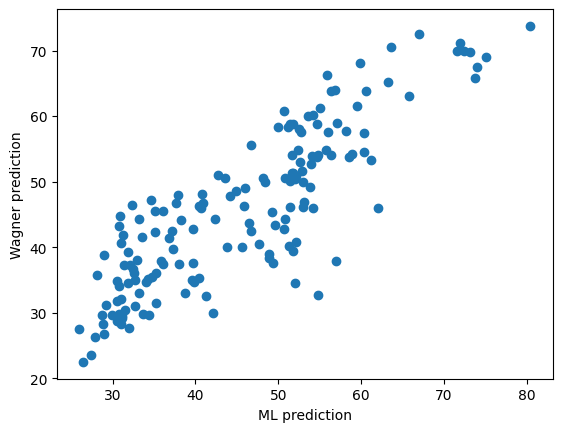

In [75]:
plt.scatter(compare["ogt_final"], compare["wagner_prediction_ogt"])
plt.xlabel("ML prediction")
plt.ylabel("Wagner prediction")